In [11]:
!pip install pmdarima

Loaded from Drive: /content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv | Shape: (10819, 11)

=== BASIC INSPECTION ===
Columns: ['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_Price', 'Max_Price', 'Modal_Price', 'Commodity_Code']

Dtypes:
 State              object
District           object
Market             object
Commodity          object
Variety            object
Grade              object
Arrival_Date       object
Min_Price           int64
Max_Price           int64
Modal_Price       float64
Commodity_Code      int64
dtype: object

Rows: 10819

Missing values:
 State             0
District          0
Market            0
Commodity         0
Variety           0
Grade             0
Arrival_Date      0
Min_Price         0
Max_Price         0
Modal_Price       0
Commodity_Code    0
dtype: int64

Duplicate rows: 0

Summary stats (numeric):
                   count         mean          std    min     25%     50%  \
Mi

/tmp/ipykernel_985/3592068301.py:220: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  panel = panel.groupby(["commodity", "market"], group_keys=False).apply(add_supply_indicators)


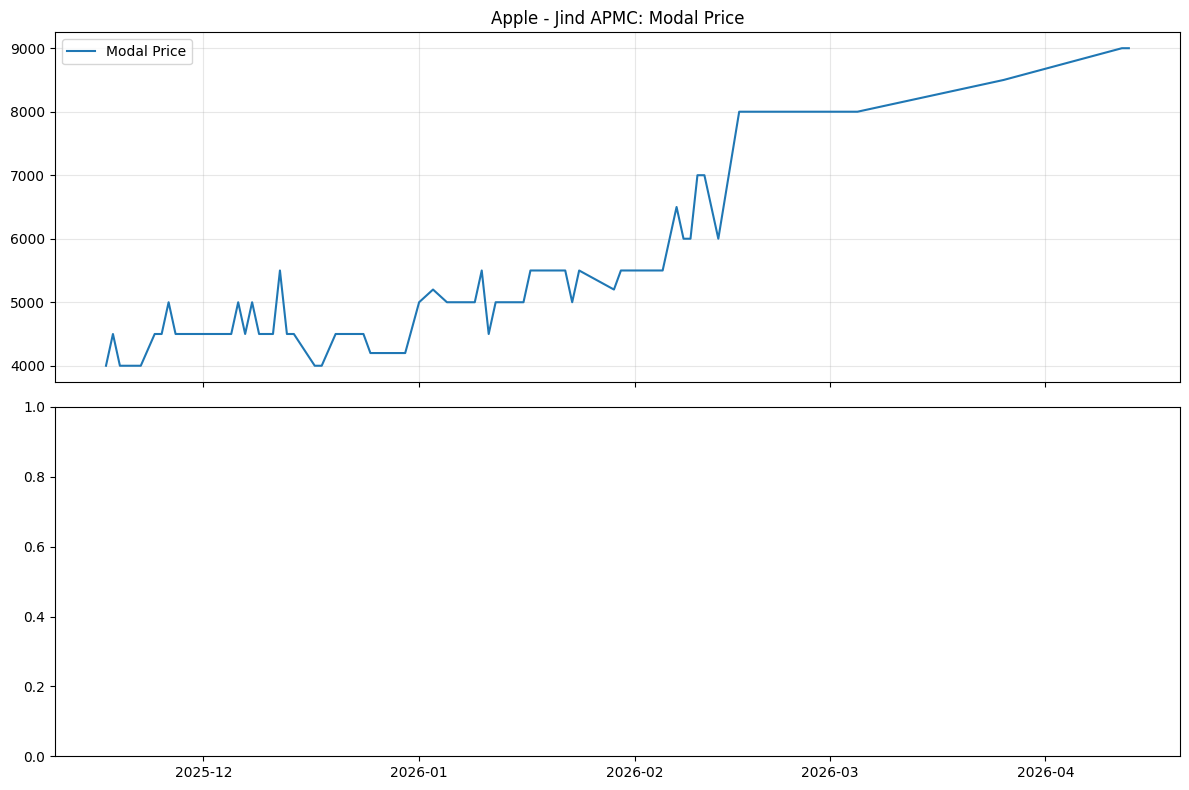

/tmp/ipykernel_985/3592068301.py:285: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  feat = panel.groupby(["commodity", "market"], group_keys=False).apply(engineer_features)


Feature matrix shape: (8857, 18)


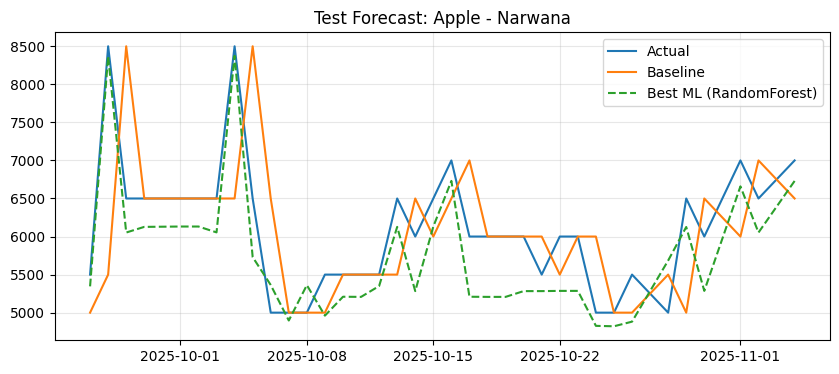

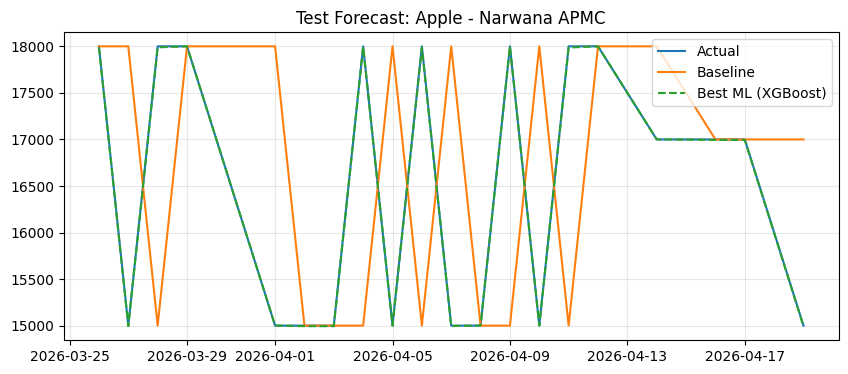

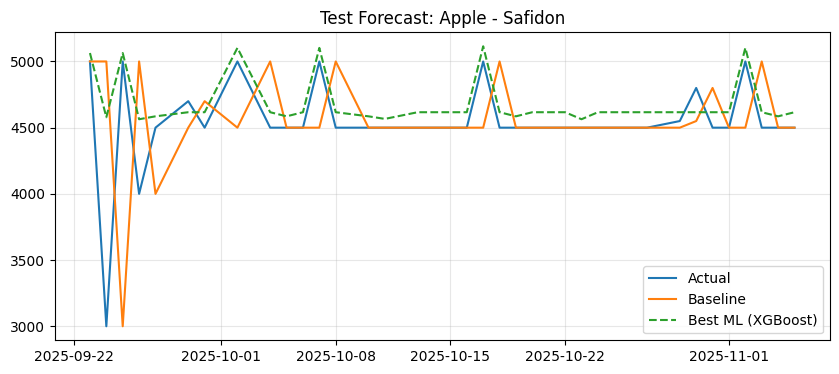

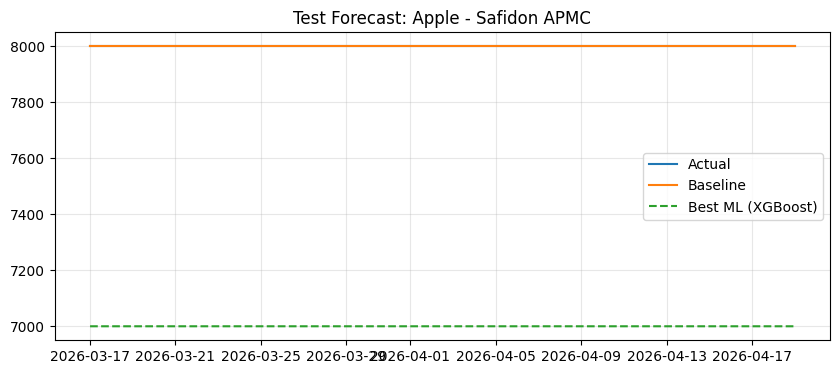

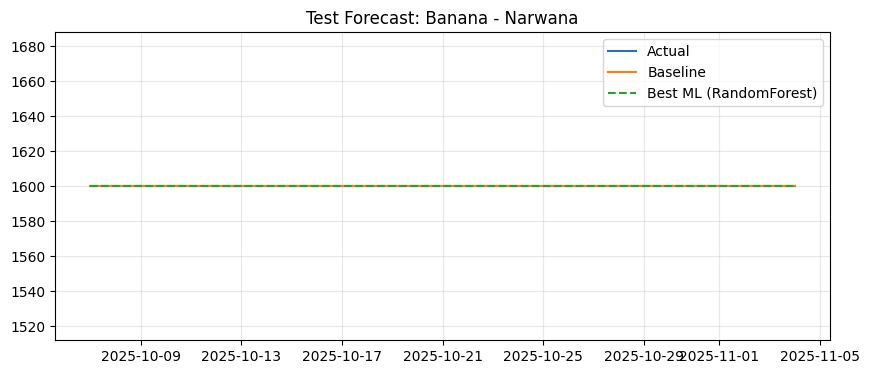

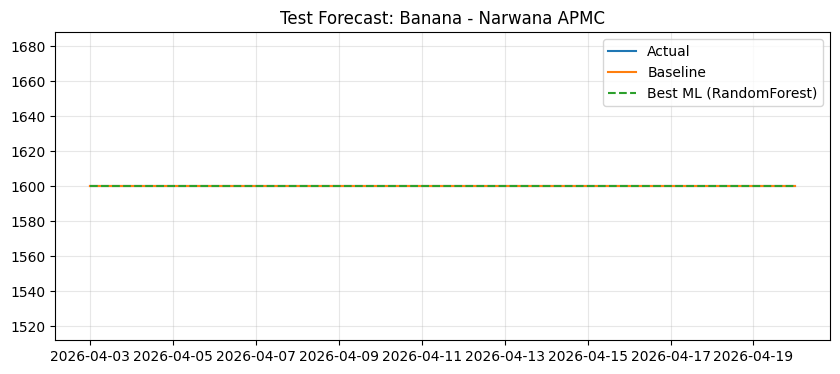

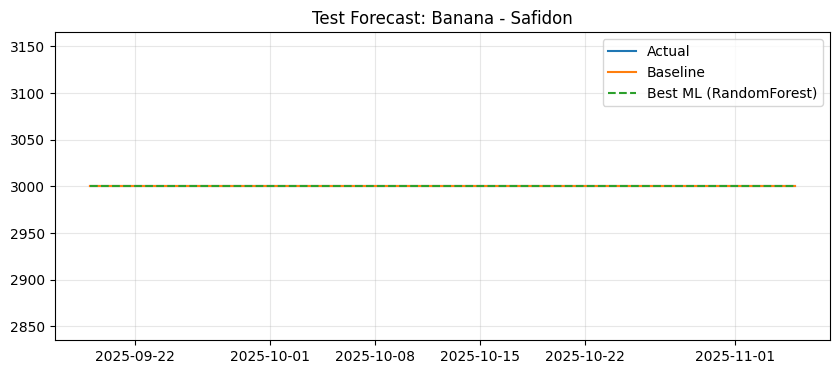

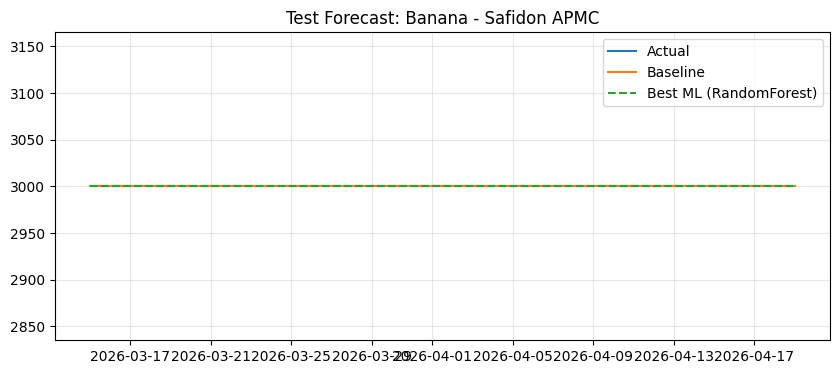

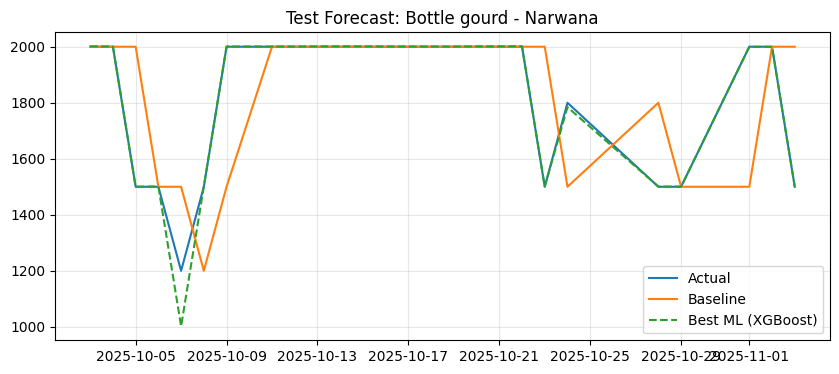

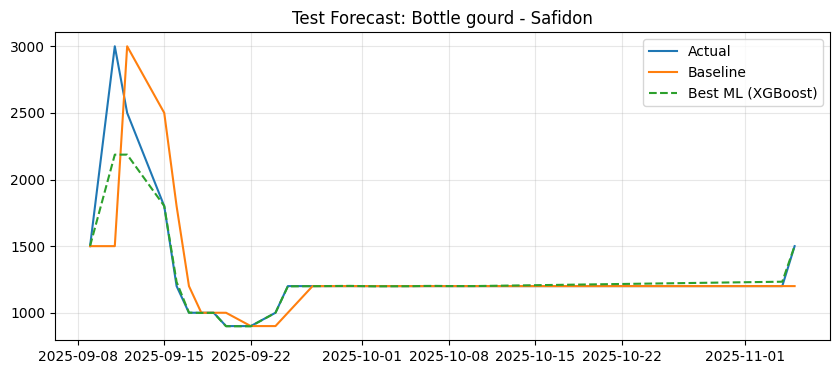

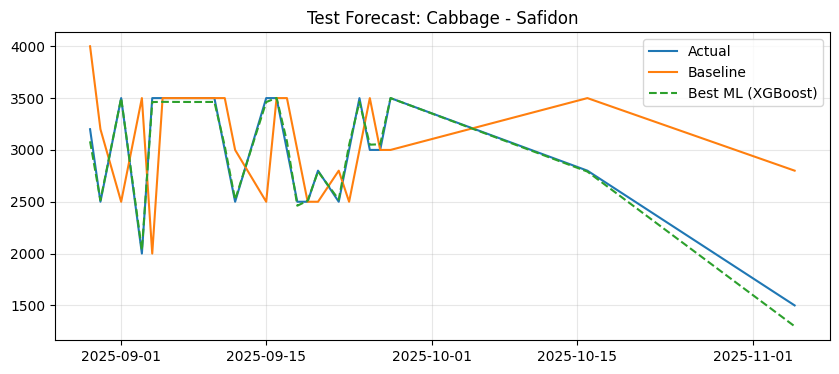

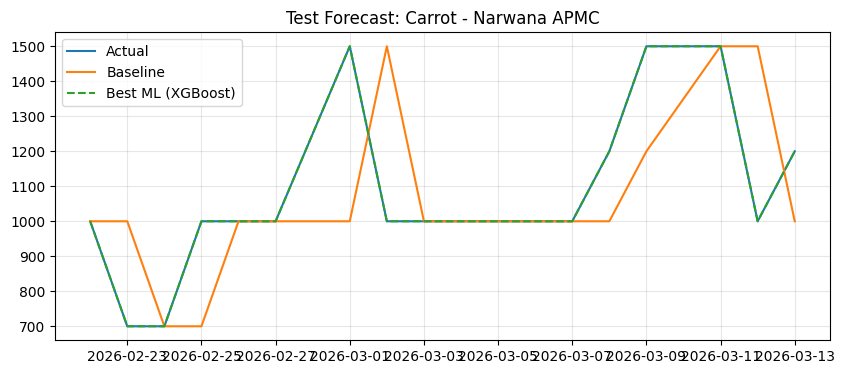

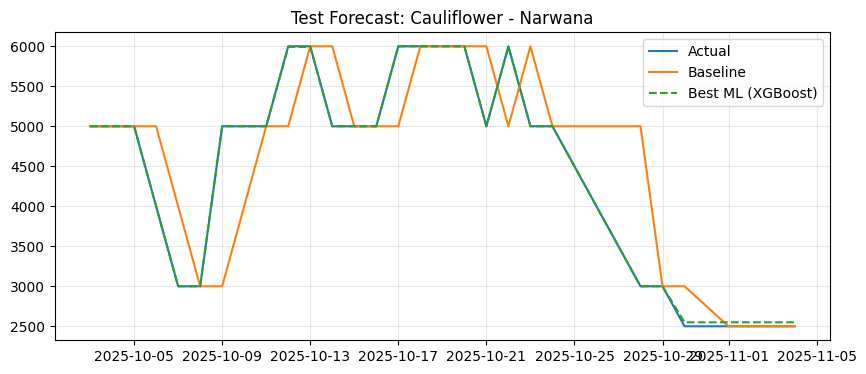

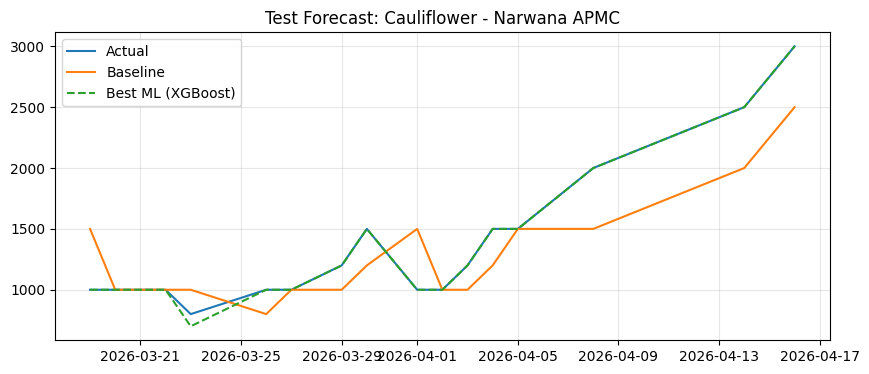

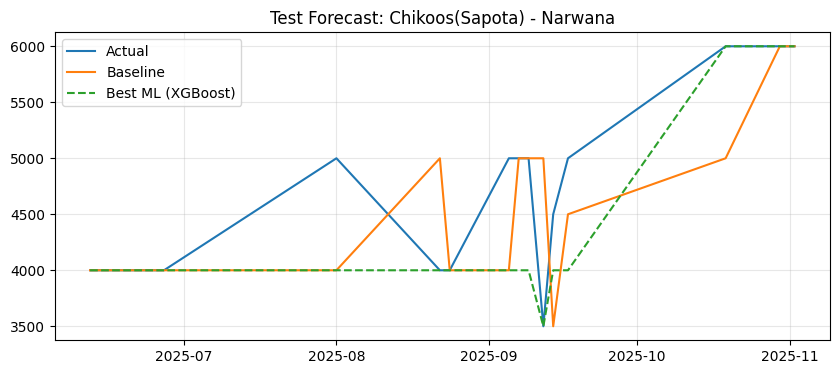

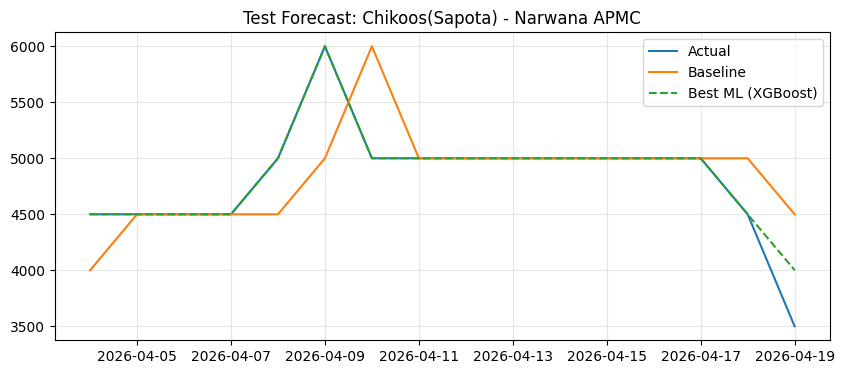

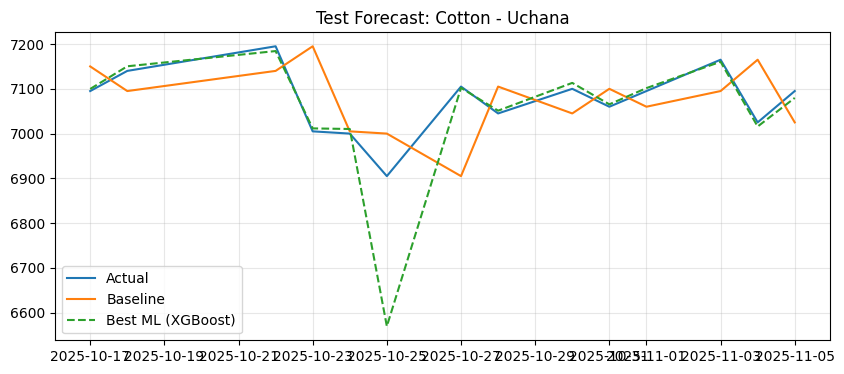

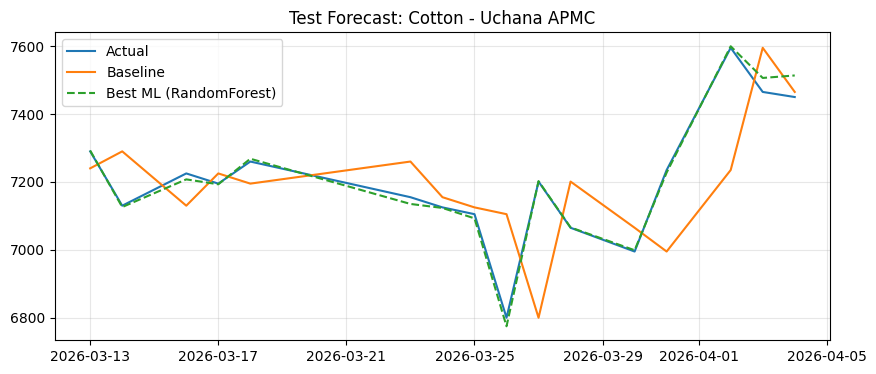

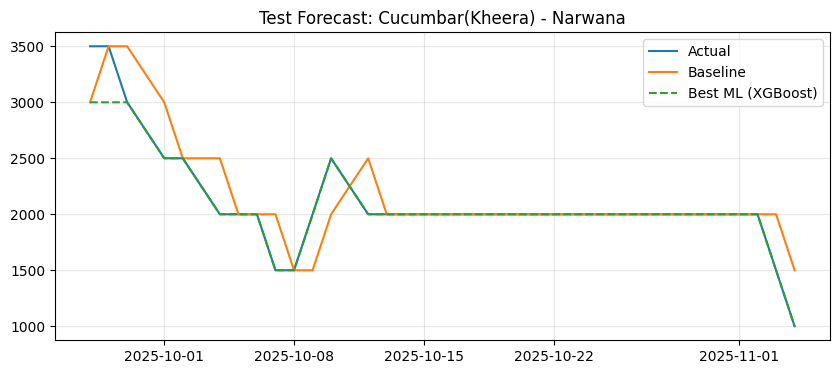

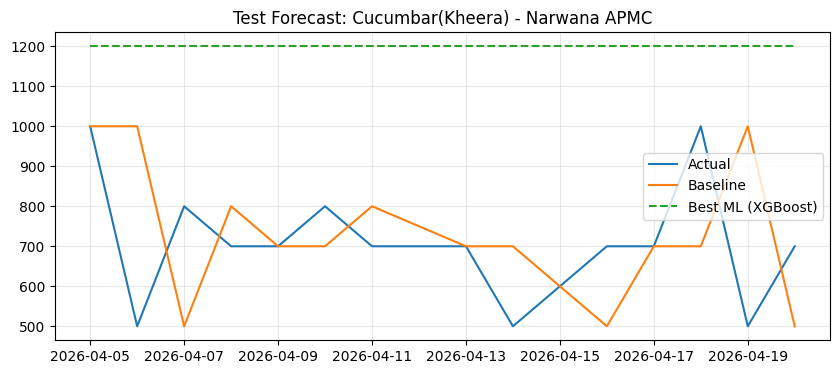

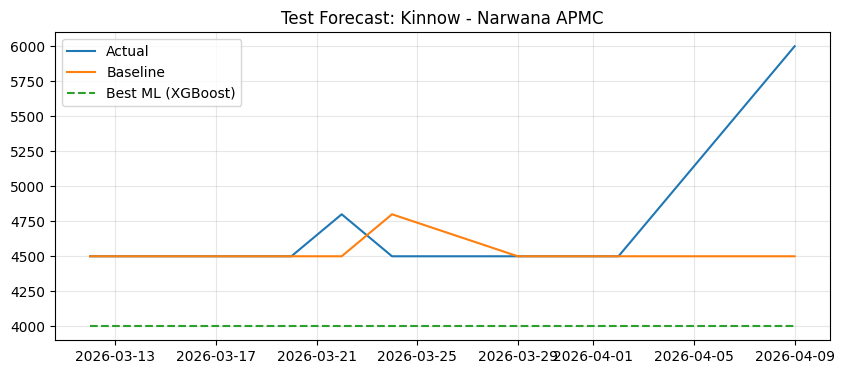

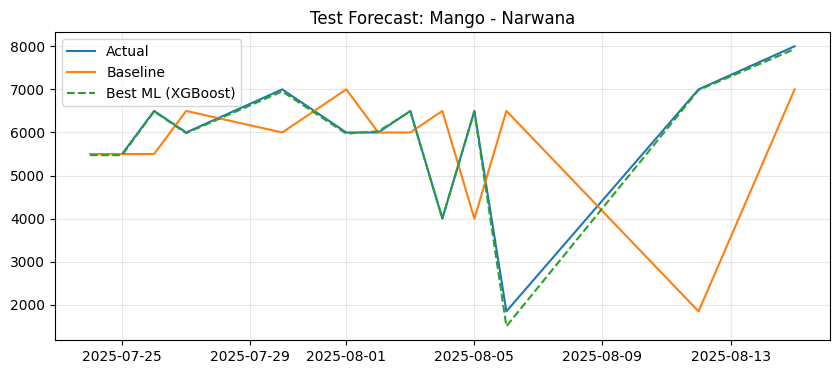

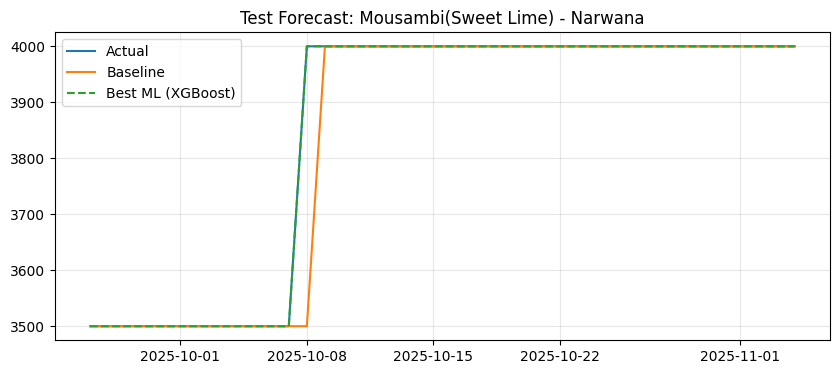

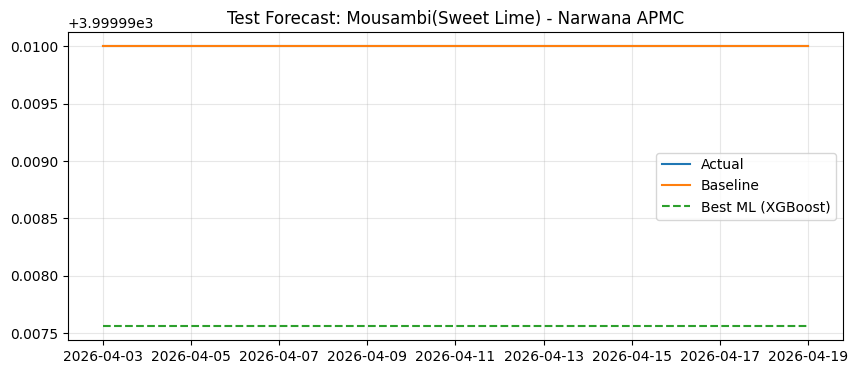

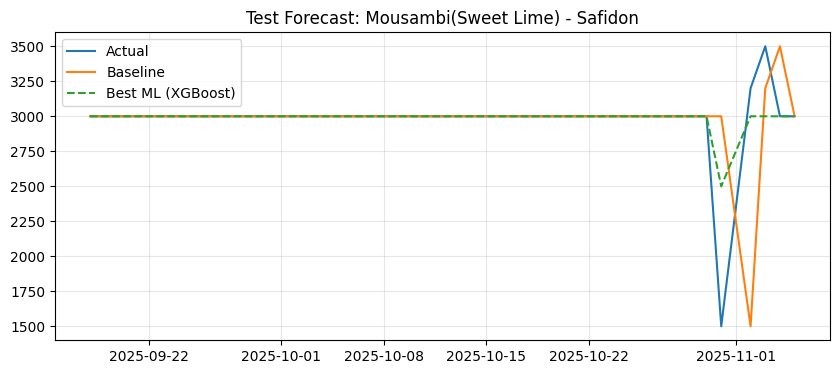

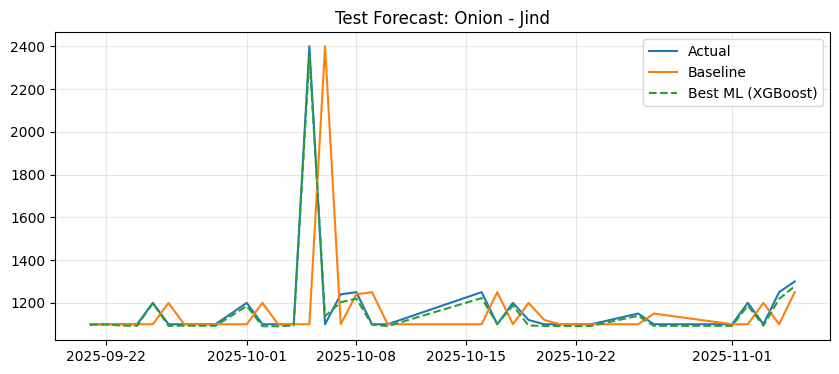

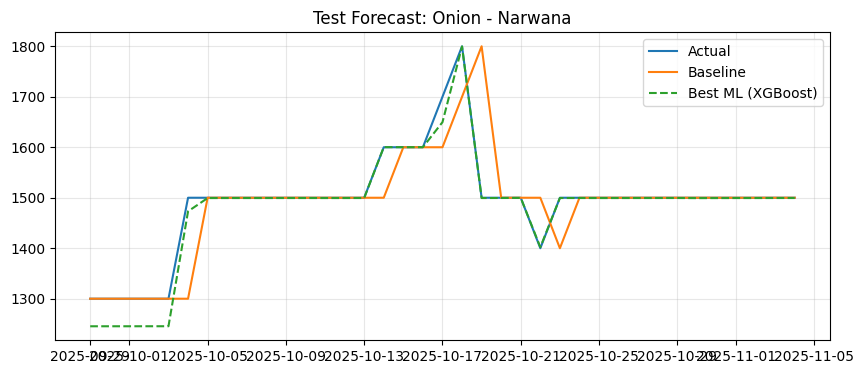

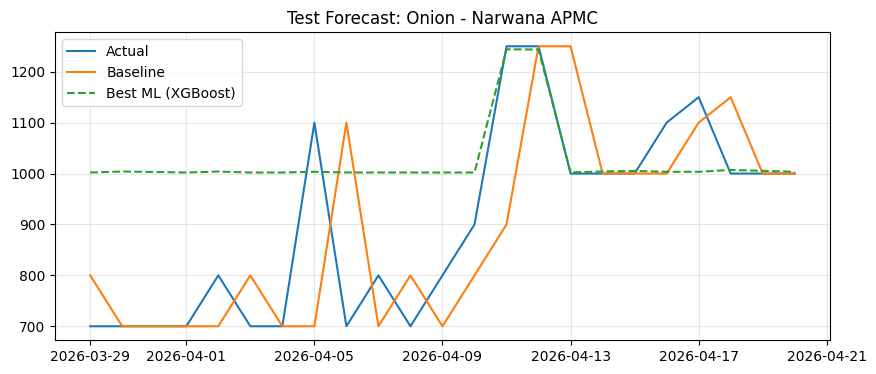

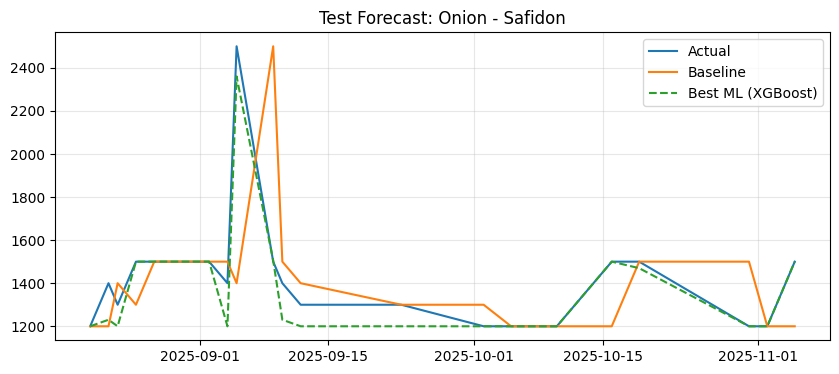

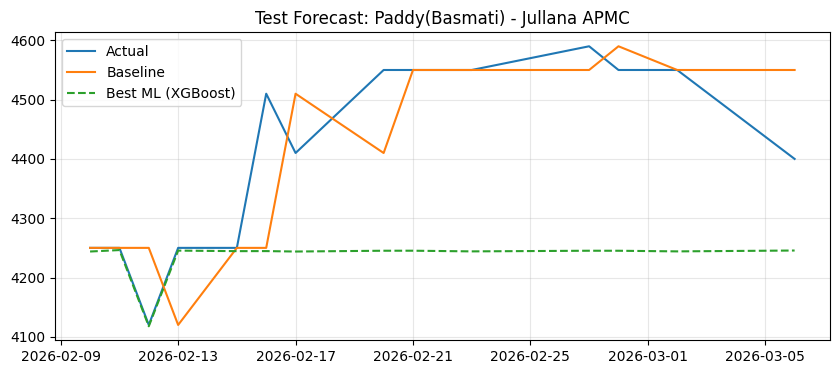

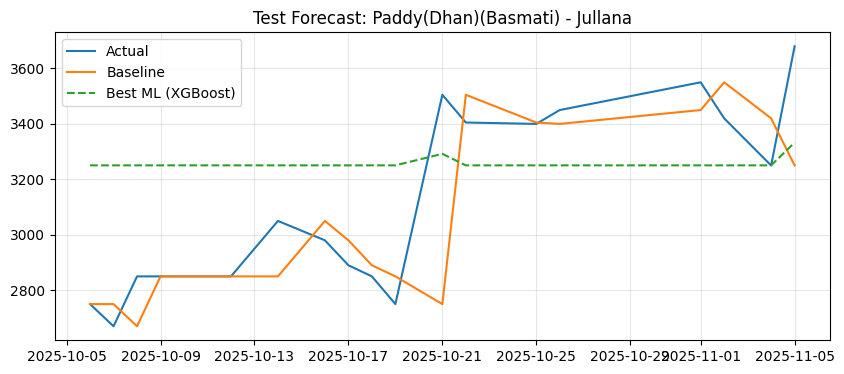

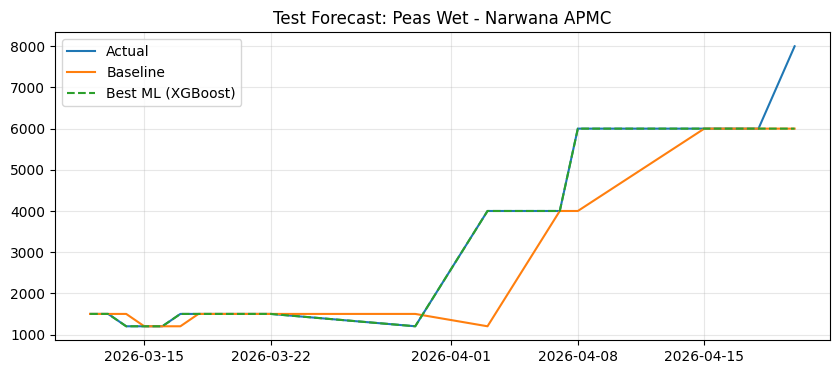

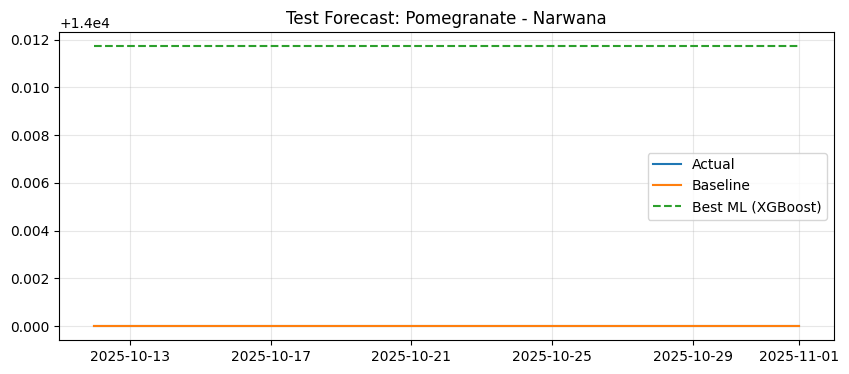

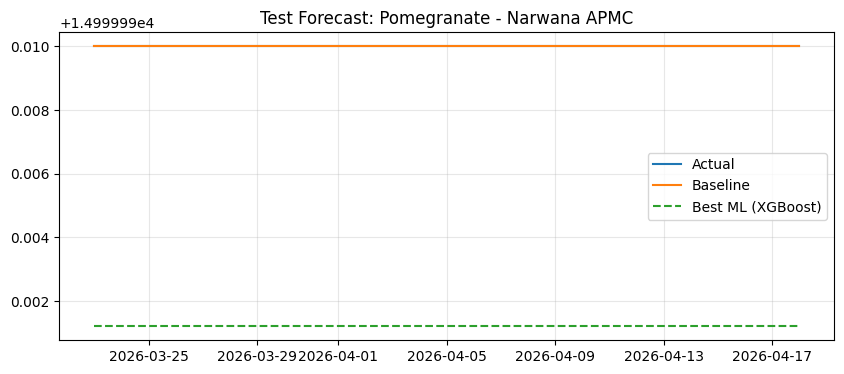

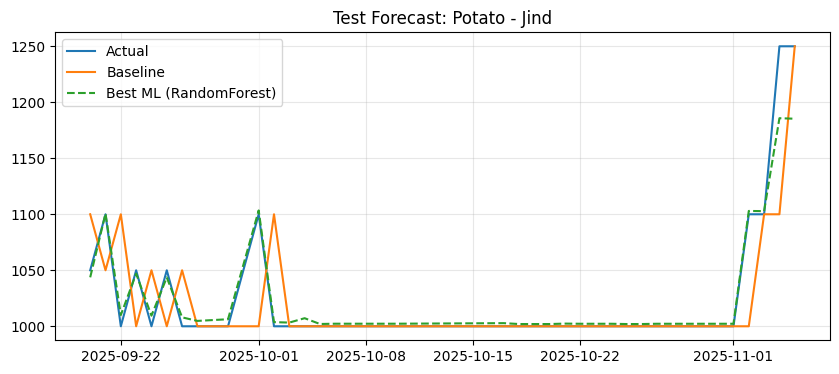

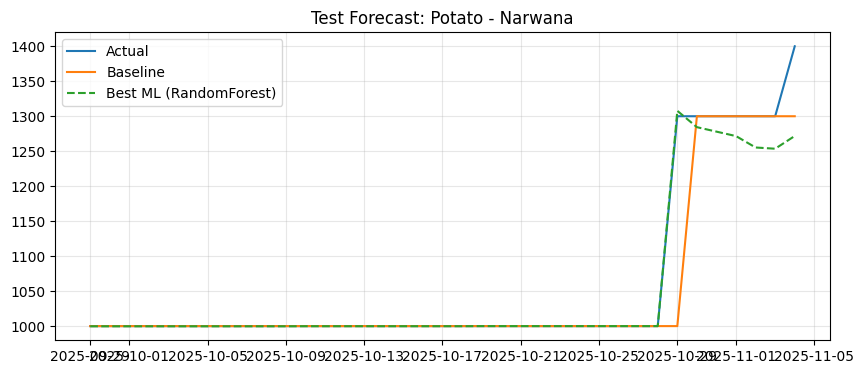

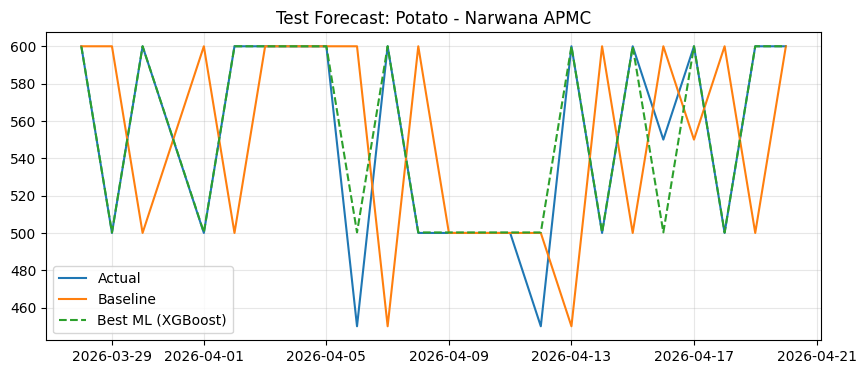

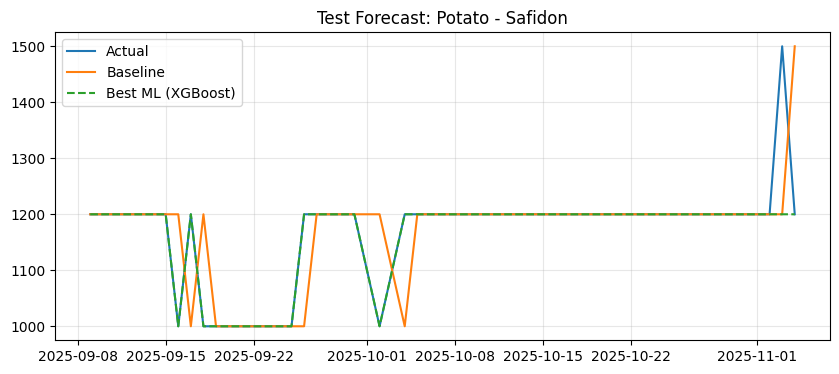

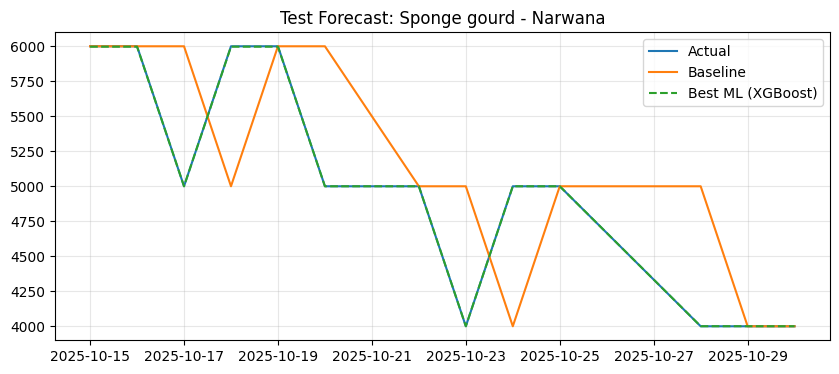

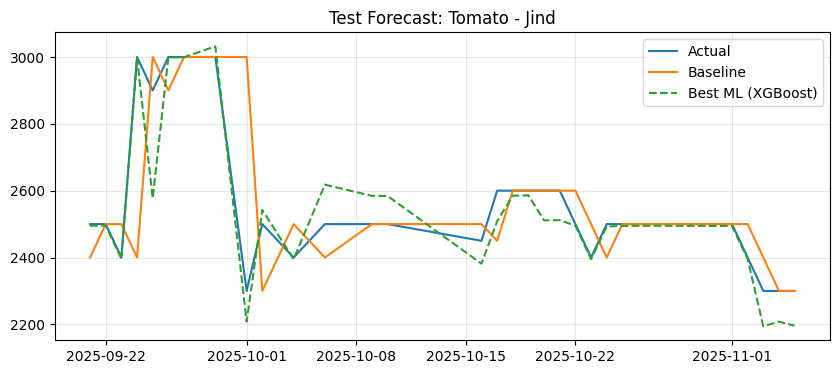

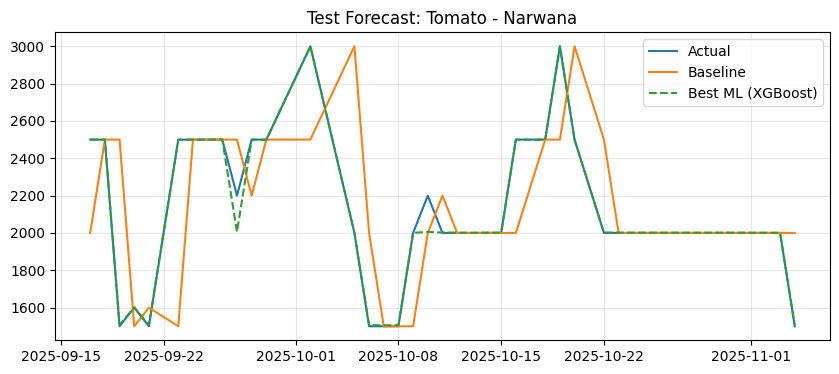

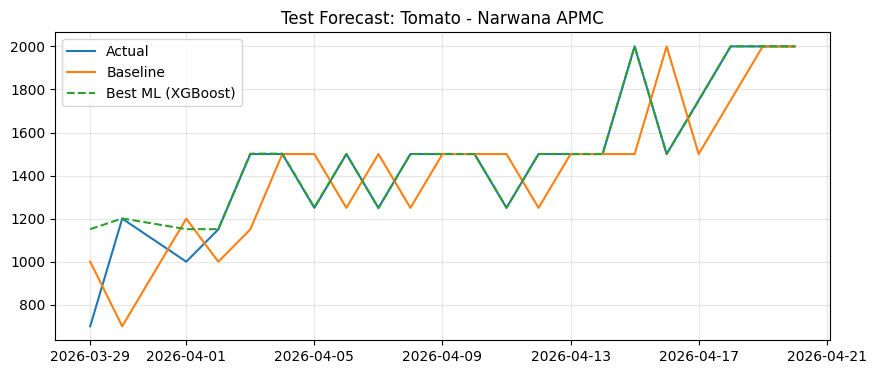

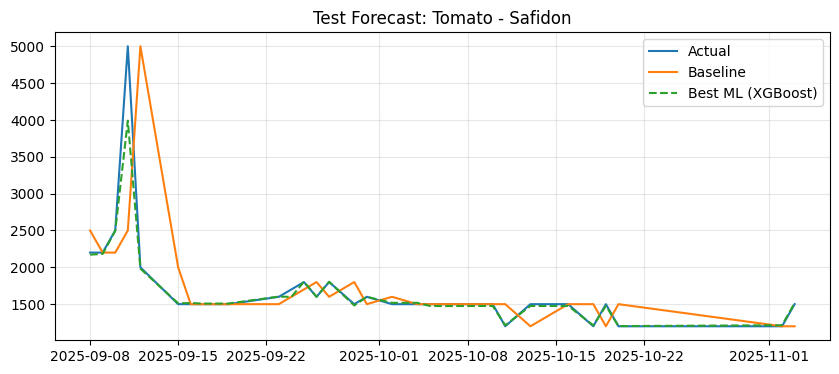


=== Model Evaluation ===


,commodity,market,model,MAE,RMSE,R2
2,Apple,Narwana,RandomForest,431.991826,485.701497,0.665773
1,Apple,Narwana,Baseline_LastPrice,611.111111,950.146188,-0.279038
0,Apple,Narwana,XGBoost,634.093533,798.833715,0.095902
3,Apple,Narwana APMC,XGBoost,4.743311,6.298070,0.999980
5,Apple,Narwana APMC,RandomForest,240.855556,282.017704,0.959213
...,...,...,...,...,...,...
125,Tomato,Narwana APMC,RandomForest,51.945473,127.778643,0.846711
124,Tomato,Narwana APMC,Baseline_LastPrice,204.545455,263.283463,0.349207
126,Tomato,Safidon,XGBoost,50.170443,185.957296,0.924646
128,Tomato,Safidon,RandomForest,130.348302,278.730039,0.830703


ValueError: Model not found for ('Apple', 'Jind APMC', 'RandomForest')

In [12]:
import pandas as pd
import numpy as np
import os
import json
import joblib
from datetime import datetime
from typing import Dict, List, Optional, Tuple
from google.colab import files
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# =========================
# AgriSense End-to-End Notebook Cell (Colab)
# =========================

# ---------- Section 0: Minimal setup ----------
try:
    pd
except NameError:
    import pandas as pd

try:
    np
except NameError:
    import numpy as np

try:
    plt
except NameError:
    import matplotlib.pyplot as plt

try:
    HAS_XGB = True
except Exception:
    HAS_XGB = False

# ---------- Section 1: Load CSV from Google Drive ----------
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except Exception:
    pass

import glob
price_path_candidates = [
    "/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv",
    "/content/drive/MyDrive/agrisense_project/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv",
    "/content/drive/MyDrive/agmarknet_india_historical_prices_2024_2025.csv",
]
raw_file_path = next((p for p in price_path_candidates if os.path.exists(p)), None)

if raw_file_path is None:
    discovered = glob.glob('/content/drive/MyDrive/**/*JIND*Commodity*.csv', recursive=True)
    if not discovered:
        discovered = glob.glob('/content/drive/MyDrive/**/*price*.csv', recursive=True)
    if discovered:
        raw_file_path = discovered[0]

if raw_file_path is None:
    raise FileNotFoundError("Price CSV not found in Google Drive. Update `price_path_candidates` with your uploaded file location.")

df_raw = pd.read_csv(raw_file_path)
print(f"Loaded from Drive: {raw_file_path} | Shape: {df_raw.shape}")

# ---------- Section 2: Dataset inspection ----------
def inspect_dataset(df: pd.DataFrame) -> None:
    print("\n=== BASIC INSPECTION ===")
    print("Columns:", list(df.columns))
    print("\nDtypes:\n", df.dtypes)
    print("\nRows:", len(df))
    print("\nMissing values:\n", df.isna().sum().sort_values(ascending=False))
    print("\nDuplicate rows:", df.duplicated().sum())
    print("\nSummary stats (numeric):\n", df.describe(include=[np.number]).T if df.select_dtypes(include=[np.number]).shape[1] else "No numeric columns")

inspect_dataset(df_raw)

# ---------- Section 3: Column mapping (transparent, no silent guessing) ----------
COLUMN_CANDIDATES = {
    "date": ["arrival_date", "date", "reported_date"],
    "commodity": ["commodity", "crop", "item"],
    "market": ["market", "mandi"],
    "state": ["state"],
    "district": ["district"],
    "arrival_qty": ["arrival_quantity", "arrivals", "arrivals_qty", "arrival qty", "quantity", "arrival"],
    "min_price": ["min_price", "minimum_price", "min price"],
    "max_price": ["max_price", "maximum_price", "max price"],
    "modal_price": ["modal_price", "price", "modal price"]
}

def auto_suggest_mapping(df: pd.DataFrame) -> Dict[str, Optional[str]]:
    lc_cols = {c.lower().strip(): c for c in df.columns}
    mapping = {}
    for canon, candidates in COLUMN_CANDIDATES.items():
        found = None
        for cand in candidates:
            if cand in lc_cols:
                found = lc_cols[cand]
                break
        mapping[canon] = found
    return mapping

suggested_mapping = auto_suggest_mapping(df_raw)
print("\n=== Suggested column mapping ===")
for k, v in suggested_mapping.items():
    print(f"{k:12s} -> {v}")

print("\nIf any mapping is wrong/missing, edit manual_mapping below and rerun this cell.")
manual_mapping = {
    # Example:
    # "arrival_qty": "Arrivals (Tonnes)",
    # "modal_price": "Modal_Price"
}

for k, v in manual_mapping.items():
    suggested_mapping[k] = v

required = ["date", "commodity", "market", "modal_price"]
missing_required = [k for k in required if not suggested_mapping.get(k)]
if missing_required:
    raise ValueError(f"Missing required mapped columns: {missing_required}. Please provide manual_mapping.")

# ---------- Section 4: Standardize + clean ----------
def normalize_text(s: pd.Series) -> pd.Series:
    return s.astype(str).str.strip()

def season_from_month(m: int) -> str:
    if m in [12, 1, 2]:
        return "Winter"
    if m in [3, 4, 5]:
        return "Summer"
    if m in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-Monsoon"

df = df_raw.copy()
rename_map = {v: k for k, v in suggested_mapping.items() if v is not None}
df = df.rename(columns=rename_map)

for c in ["commodity", "market", "state", "district"]:
    if c in df.columns:
        df[c] = normalize_text(df[c])

df["date"] = pd.to_datetime(df["date"], errors="coerce", dayfirst=True)
for c in ["arrival_qty", "min_price", "max_price", "modal_price"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Flags (no hard deletion of outliers)
df["flag_invalid_price"] = (df["modal_price"] <= 0) | df["modal_price"].isna()
if "arrival_qty" in df.columns:
    df["flag_invalid_arrival"] = (df["arrival_qty"] < 0) | df["arrival_qty"].isna()
else:
    df["flag_invalid_arrival"] = True

# IQR outlier flags
def iqr_flag(x: pd.Series) -> pd.Series:
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (x < lo) | (x > hi)

grp_cols = [c for c in ["commodity", "market"] if c in df.columns]
df["flag_price_outlier"] = False
if grp_cols:
    df["flag_price_outlier"] = df.groupby(grp_cols)["modal_price"].transform(iqr_flag)

if "arrival_qty" in df.columns:
    df["flag_arrival_outlier"] = False
    if grp_cols:
        df["flag_arrival_outlier"] = df.groupby(grp_cols)["arrival_qty"].transform(iqr_flag)

# Date range + unique commodity/market
print("\n=== CLEANING SUMMARY ===")
print("Date range:", df["date"].min(), "to", df["date"].max())
if "commodity" in df.columns:
    print("Commodities:", sorted(df["commodity"].dropna().unique())[:20], "...")
if "market" in df.columns:
    print("Markets:", sorted(df["market"].dropna().unique())[:20], "...")
print("Invalid modal price rows:", int(df["flag_invalid_price"].sum()))
print("Duplicate full rows:", int(df.duplicated().sum()))

# ---------- Section 5: Reporting-unit check + safe aggregation ----------
key_cols = [c for c in ["date", "commodity", "market", "state", "district"] if c in df.columns]
dup_key_count = df.duplicated(subset=key_cols).sum() if key_cols else 0
print("\nPossible repeated records on reporting keys:", int(dup_key_count))
print("Note: arrivals are treated as reported market arrivals proxy, not total regional supply.")

agg_cols = {
    "modal_price": "mean",
    "min_price": "mean" if "min_price" in df.columns else None,
    "max_price": "mean" if "max_price" in df.columns else None,
    "arrival_qty": "sum" if "arrival_qty" in df.columns else None,
}
agg_cols = {k: v for k, v in agg_cols.items() if v is not None}

panel = (
    df.dropna(subset=["date", "commodity", "market", "modal_price"])
.groupby(["commodity", "market", "date"], as_index=False)
.agg(agg_cols)
.sort_values(["commodity", "market", "date"])
)
print("Panel shape:", panel.shape)

# ---------- Section 6: Supply analysis indicators ----------
def add_supply_indicators(g: pd.DataFrame) -> pd.DataFrame:
    g = g.sort_values("date").copy()
    if "arrival_qty" in g.columns:
        g["arrivals_ma_7_obs"] = g["arrival_qty"].shift(1).rolling(7, min_periods=2).mean()
        g["arrivals_ma_30_obs"] = g["arrival_qty"].shift(1).rolling(30, min_periods=5).mean()
        g["arrivals_change"] = g["arrival_qty"].diff()
        g["arrivals_pct_change"] = np.where(g["arrival_qty"].shift(1) > 0, g["arrival_qty"].pct_change() * 100, np.nan)
        z = (g["arrival_qty"] - g["arrival_qty"].mean()) / (g["arrival_qty"].std() + 1e-9)
        g["arrivals_alert"] = np.where(z > 2, "Unusually High", np.where(z < -2, "Unusually Low", "Normal"))
    g["month"] = g["date"].dt.month
    g["season"] = g["month"].map(season_from_month)
    return g

panel = panel.groupby(["commodity", "market"], group_keys=False).apply(add_supply_indicators)

# ---------- Section 7: EDA plots ----------
def plot_market_series(data: pd.DataFrame, commodity: str, market: str):
    g = data[(data["commodity"] == commodity) & (data["market"] == market)].sort_values("date")
    if g.empty:
        print("No data for selection.")
        return
    fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    ax[0].plot(g["date"], g["modal_price"], label="Modal Price")
    ax[0].set_title(f"{commodity} - {market}: Modal Price")
    ax[0].grid(True, alpha=0.3)
    ax[0].legend()
    if "arrival_qty" in g.columns:
        ax[1].plot(g["date"], g["arrival_qty"], label="Arrival Qty", alpha=0.7)
        if "arrivals_ma_7_obs" in g.columns:
            ax[1].plot(g["date"], g["arrivals_ma_7_obs"], label="Arrival MA(7 obs)")
        if "arrivals_ma_30_obs" in g.columns:
            ax[1].plot(g["date"], g["arrivals_ma_30_obs"], label="Arrival MA(30 obs)")
        ax[1].set_title("Arrivals (market supply proxy)")
        ax[1].legend()
        ax[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def plot_price_vs_arrivals(data: pd.DataFrame, commodity: str, market: str):
    g = data[(data["commodity"] == commodity) & (data["market"] == market)]
    if g.empty or "arrival_qty" not in g.columns:
        return
    plt.figure(figsize=(6, 4))
    plt.scatter(g["arrival_qty"], g["modal_price"], alpha=0.5)
    plt.xlabel("Arrival Quantity")
    plt.ylabel("Modal Price")
    plt.title(f"{commodity} - {market}: Price vs Arrivals")
    plt.grid(True, alpha=0.3)
    plt.show()
    print("Interpretation: correlation does not imply causation; price and traded quantity are jointly determined.")

sample_commodity = panel["commodity"].iloc[0]
sample_market = panel["market"].iloc[0]
plot_market_series(panel, sample_commodity, sample_market)
plot_price_vs_arrivals(panel, sample_commodity, sample_market)

# ---------- Section 8: Feature engineering (past-only, no leakage) ----------
def engineer_features(g: pd.DataFrame) -> pd.DataFrame:
    g = g.sort_values("date").copy()
    g["target"] = g["modal_price"]

    for lag in [1, 2, 3, 7, 14]:
        g[f"price_lag_{lag}"] = g["modal_price"].shift(lag)
    g["price_roll_mean_7"] = g["modal_price"].shift(1).rolling(7, min_periods=2).mean()
    g["price_roll_mean_30"] = g["modal_price"].shift(1).rolling(30, min_periods=5).mean()

    if "arrival_qty" in g.columns:
        for lag in [1, 2, 3, 7, 14]:
            g[f"arrival_lag_{lag}"] = g["arrival_qty"].shift(lag)
        g["arrival_roll_mean_7"] = g["arrival_qty"].shift(1).rolling(7, min_periods=2).mean()
        g["arrival_roll_mean_30"] = g["arrival_qty"].shift(1).rolling(30, min_periods=5).mean()

    g["month"] = g["date"].dt.month
    g["day_of_week"] = g["date"].dt.dayofweek
    g["season_code"] = g["month"].map(lambda m: {"Winter":0, "Summer":1, "Monsoon":2, "Post-Monsoon":3}[season_from_month(m)])

    return g.dropna().copy()

feat = panel.groupby(["commodity", "market"], group_keys=False).apply(engineer_features)
print("Feature matrix shape:", feat.shape)

# ---------- Section 9: Train/val/test + models ----------
def split_chrono(g: pd.DataFrame, tr=0.7, va=0.15):
    n = len(g)
    i1, i2 = int(n * tr), int(n * (tr + va))
    return g.iloc[:i1], g.iloc[i1:i2], g.iloc[i2:]

def metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan
    }

results = []
trained_models = {}  # key=(commodity, market, model_name)

for (c, m), g in feat.groupby(["commodity", "market"]):
    g = g.sort_values("date")
    if len(g) < 80:
        continue

    train, val, test = split_chrono(g)
    feature_cols = [x for x in g.columns if x not in ["commodity", "market", "date", "target", "season"]]
    X_train, y_train = train[feature_cols], train["target"]
    X_val, y_val = val[feature_cols], val["target"]
    X_test, y_test = test[feature_cols], test["target"]

    # Baseline: previous observed price
    yhat_val_base = val["price_lag_1"]
    yhat_test_base = test["price_lag_1"]
    res_base = metrics(y_test, yhat_test_base)

    # Random Forest
    rf = RandomForestRegressor(n_estimators=300, random_state=42, min_samples_leaf=2)
    rf.fit(X_train, y_train)
    yhat_val_rf = rf.predict(X_val)
    yhat_test_rf = rf.predict(X_test)
    res_rf = metrics(y_test, yhat_test_rf)

    # XGBoost (optional)
    best_name, best_model, best_pred = "RandomForest", rf, yhat_test_rf
    best_mae = res_rf["MAE"]

    if HAS_XGB:
        xgbr = xgb.XGBRegressor(
            n_estimators=300, max_depth=4, learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9, random_state=42
        )
        xgbr.fit(X_train, y_train)
        yhat_test_xgb = xgbr.predict(X_test)
        res_xgb = metrics(y_test, yhat_test_xgb)
        results.append({"commodity": c, "market": m, "model": "XGBoost", **res_xgb})
        trained_models[(c, m, "XGBoost")] = (xgbr, feature_cols)
        if res_xgb["MAE"] < best_mae:
            best_name, best_model, best_pred, best_mae = "XGBoost", xgbr, yhat_test_xgb, res_xgb["MAE"]

    results.append({"commodity": c, "market": m, "model": "Baseline_LastPrice", **res_base})
    results.append({"commodity": c, "market": m, "model": "RandomForest", **res_rf})
    trained_models[(c, m, "RandomForest")] = (rf, feature_cols)

    # Test plot
    plt.figure(figsize=(10, 4))
    plt.plot(test["date"], y_test.values, label="Actual")
    plt.plot(test["date"], yhat_test_base.values, label="Baseline")
    plt.plot(test["date"], best_pred, label=f"Best ML ({best_name})", linestyle="--")
    plt.title(f"Test Forecast: {c} - {m}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

eval_df = pd.DataFrame(results).sort_values(["commodity", "market", "MAE"])
print("\n=== Model Evaluation ===")
display(eval_df)

# ---------- Section 10: Forecasting (recursive, no future actuals) ----------
def infer_step_days(g: pd.DataFrame) -> int:
    diffs = g["date"].sort_values().diff().dt.days.dropna()
    if diffs.empty:
        return 1
    return int(max(1, diffs.mode().iloc[0]))

def recursive_forecast(
    feat_df: pd.DataFrame,
    commodity: str,
    market: str,
    horizon_days: int,
    model_name: str = "RandomForest",
    future_arrivals: Optional[List[float]] = None
) -> pd.DataFrame:
    key = (commodity, market, model_name)
    if key not in trained_models:
        raise ValueError(f"Model not found for {key}")
    model, feature_cols = trained_models[key]

    g = panel[(panel["commodity"] == commodity) & (panel["market"] == market)].sort_values("date").copy()
    if g.empty:
        raise ValueError("No history for selected commodity-market.")

    step_days = infer_step_days(g)
    hist_prices = list(g["modal_price"].values)
    if "arrival_qty" in g.columns:
        hist_arr = list(g["arrival_qty"].fillna(method="ffill").fillna(0).values)
    else:
        hist_arr = [0.0] * len(hist_prices)

    last_date = g["date"].iloc[-1]
    rows = []
    for h in range(1, horizon_days + 1):
        d = last_date + pd.Timedelta(days=step_days * h)
        arr_h = future_arrivals[h - 1] if (future_arrivals is not None and h - 1 < len(future_arrivals)) else hist_arr[-1]

        def lag(v, k): return v[-k] if len(v) >= k else np.nan
        x = {
            "price_lag_1": lag(hist_prices, 1), "price_lag_2": lag(hist_prices, 2), "price_lag_3": lag(hist_prices, 3),
            "price_lag_7": lag(hist_prices, 7), "price_lag_14": lag(hist_prices, 14),
            "price_roll_mean_7": np.mean(hist_prices[-7:]) if len(hist_prices) >= 2 else np.nan,
            "price_roll_mean_30": np.mean(hist_prices[-30:]) if len(hist_prices) >= 5 else np.nan,
            "arrival_lag_1": lag(hist_arr, 1), "arrival_lag_2": lag(hist_arr, 2), "arrival_lag_3": lag(hist_arr, 3),
            "arrival_lag_7": lag(hist_arr, 7), "arrival_lag_14": lag(hist_arr, 14),
            "arrival_roll_mean_7": np.mean(hist_arr[-7:]) if len(hist_arr) >= 2 else np.nan,
            "arrival_roll_mean_30": np.mean(hist_arr[-30:]) if len(hist_arr) >= 5 else np.nan,
            "month": d.month, "day_of_week": d.dayofweek,
            "season_code": {"Winter":0, "Summer":1, "Monsoon":2, "Post-Monsoon":3}[season_from_month(d.month)],
        }
        x_df = pd.DataFrame([x])
        for col in feature_cols:
            if col not in x_df.columns:
                x_df[col] = 0.0
        x_df = x_df[feature_cols].fillna(method="ffill", axis=1).fillna(0.0)
        yhat = float(model.predict(x_df)[0])

        rows.append({"forecast_date": d, "pred_modal_price": yhat, "assumed_arrival_qty": arr_h})
        hist_prices.append(yhat)
        hist_arr.append(arr_h)

    return pd.DataFrame(rows)

# User selection
selected_commodity = sample_commodity
selected_market = sample_market
forecast_horizon_days = 7

forecast_df = recursive_forecast(feat, selected_commodity, selected_market, forecast_horizon_days, model_name="RandomForest")
print("\nForecast:")
display(forecast_df)

# ---------- Section 11: MSP module ----------
def msp_analysis(
    historical_prices: pd.Series,
    forecast_prices: pd.Series,
    msp_value: float,
    commodity: str,
    season: str
) -> Dict[str, float]:
    if msp_value is None or msp_value <= 0:
        raise ValueError("Provide a valid official MSP value.")
    hist_below = float((historical_prices < msp_value).mean() * 100) if len(historical_prices) > 0 else np.nan
    latest = float(historical_prices.iloc[-1]) if len(historical_prices) else np.nan
    avg_fc = float(forecast_prices.mean()) if len(forecast_prices) else np.nan
    gap = msp_value - avg_fc
    gap_pct = (gap / msp_value) * 100 if msp_value != 0 else np.nan

    out = {
        "commodity": commodity
        ,"season": season
        ,"msp": float(msp_value)
        ,"latest_observed_modal_price": latest
        ,"avg_forecast_modal_price": avg_fc
        ,"price_gap_msp_minus_forecast": float(gap)
        ,"price_gap_pct": float(gap_pct)
        ,"historical_below_msp_pct": float(hist_below)
    }
    return out

# Set MSP manually (official source needed)
official_msp_value = 4500.0  # Replace with verified official MSP when applicable
hist_series = panel[(panel["commodity"] == selected_commodity) & (panel["market"] == selected_market)]["modal_price"]
msp_report = msp_analysis(hist_series, forecast_df["pred_modal_price"], official_msp_value, selected_commodity, "User-Specified")
print("\nMSP report:")
print(json.dumps(msp_report, indent=2))

plt.figure(figsize=(10, 4))
h_recent = panel[(panel["commodity"] == selected_commodity) & (panel["market"] == selected_market)].tail(120)
plt.plot(h_recent["date"], h_recent["modal_price"], label="Recent observed")
plt.plot(forecast_df["forecast_date"], forecast_df["pred_modal_price"], "--", label="Forecast")
plt.axhline(official_msp_value, color="red", label="MSP")
plt.legend(); plt.grid(True, alpha=0.3); plt.title("MSP vs Observed/Forecast Modal Price")
plt.show()

# ---------- Section 12: Demand limitations ----------
print("\n=== Demand Estimation Limitation ===")
print("Observed arrivals and price do not identify true demand alone.")
print("Need additional variables: sold quantity, unsold stock, procurement quantities, buyer purchases, regional supply shocks, etc.")

# ---------- Section 13: MSP market-absorption scenario simulator ----------
def msp_absorption_scenarios(
    current_arrivals: float,
    current_modal_price: float,
    msp_value: float,
    additional_purchases: List[float],
    optional_price_sensitivity: Optional[float] = None
) -> pd.DataFrame:
    rows = []
    for q in additional_purchases:
        net_arrival = max(current_arrivals - q, 0)
        if optional_price_sensitivity is None:
            pred_price = np.nan
            note = "No calibrated price response model; table is quantity-only scenario."
        else:
            pred_price = current_modal_price + optional_price_sensitivity * q
            note = "Hypothetical, sensitivity supplied by user."
        gap = msp_value - pred_price if not np.isnan(pred_price) else np.nan
        rows.append({
            "additional_qty_purchased": q
            ,"net_market_arrivals_after_purchase": net_arrival
            ,"hypothetical_predicted_price": pred_price
            ,"msp_gap_if_price_modeled": gap
            ,"note": note
        })
    return pd.DataFrame(rows)

current_arr = float(h_recent["arrival_qty"].iloc[-1]) if "arrival_qty" in h_recent.columns and len(h_recent) else 0.0
current_price = float(h_recent["modal_price"].iloc[-1]) if len(h_recent) else np.nan
scenario_table = msp_absorption_scenarios(
    current_arrivals=current_arr,
    current_modal_price=current_price,
    msp_value=official_msp_value,
    additional_purchases=[0, 50, 100, 200, 400],
    optional_price_sensitivity=None
)
print("\nScenario table:")
display(scenario_table)

# ---------- Section 14: Save artifacts ----------
timestamp = datetime.utcnow().strftime("%Y%m%d_%H%M%S")
artifact = {
    "model_version": f"agrisense_v1_{timestamp}",
    "trained_at_utc": timestamp,
    "data_file": raw_file_path,
    "date_range": [str(panel["date"].min()), str(panel["date"].max())],
    "evaluation": eval_df.to_dict(orient="records"),
    "mapping": suggested_mapping,
    "models": trained_models  # (commodity, market, model) -> (estimator, feature_cols)
}
artifact_path = f"agrisense_artifact_{timestamp}.joblib"
joblib.dump(artifact, artifact_path)

panel_path = f"agrisense_cleaned_panel_{timestamp}.csv"
supply_path = f"agrisense_supply_analysis_{timestamp}.csv"
msp_path = f"agrisense_msp_report_{timestamp}.json"
scenario_path = f"agrisense_scenarios_{timestamp}.csv"
eval_path = f"agrisense_model_eval_{timestamp}.csv"

panel.to_csv(panel_path, index=False)
panel.to_csv(supply_path, index=False)
with open(msp_path, "w") as f:
    json.dump(msp_report, f, indent=2)
scenario_table.to_csv(scenario_path, index=False)
eval_df.to_csv(eval_path, index=False)

print("\nSaved files:")
for p in [artifact_path, panel_path, supply_path, msp_path, scenario_path, eval_path]:
    print("-", p)

# Optional downloads
for p in [artifact_path, panel_path, supply_path, msp_path, scenario_path, eval_path]:
    files.download(p)

# ---------- Section 15: Reusable prediction function + FastAPI-ready I/O ----------
def load_artifact(path: str):
    return joblib.load(path)

def predict_from_request(artifact_obj: dict, request_json: dict) -> dict:
    commodity = request_json["commodity"]
    market = request_json["market"]
    horizon = int(request_json.get("forecast_horizon_days", 1))
    model_name = request_json.get("model_name", "RandomForest")
    msp_value = request_json.get("msp", None)

    fc = recursive_forecast(
        feat_df=feat,
        commodity=commodity,
        market=market,
        horizon_days=horizon,
        model_name=model_name
    )

    last_row = fc.iloc[-1]
    resp = {
        "commodity": commodity,
        "market": market,
        "forecast_date": str(last_row["forecast_date"].date()),
        "predicted_modal_price": float(last_row["pred_modal_price"]),
        "price_unit": "INR per Quintal (verify with source file)",
        "model_version": artifact_obj["model_version"]
    }

    if msp_value is not None and msp_value > 0:
        gap = float(msp_value - last_row["pred_modal_price"])
        resp["applicable_msp"] = float(msp_value)
        resp["price_gap_msp_minus_forecast"] = gap
    return resp

# Example request/response
example_request = {
    "commodity": selected_commodity,
    "market": selected_market,
    "forecast_horizon_days": 1
}
artifact_loaded = load_artifact(artifact_path)
example_response = predict_from_request(artifact_loaded, example_request)
print("\nFastAPI-style example response:")
print(json.dumps(example_response, indent=2))

print("\nIntegration note: expose `predict_from_request` in FastAPI endpoint and load artifact once at service startup.")

In [13]:
import os
import logging
from typing import Tuple, Optional
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pmdarima as pm

# Configure structured logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

# ---------------------------------------------------------
# MODULE 1: DATA LOADING & ROBUST CLEANING
# ---------------------------------------------------------

def clean_string_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Strips whitespaces and normalizes case for all string-type columns."""
    df = df.copy()
    for col in df.select_dtypes(include=['object', 'string']).columns:
        df[col] = df[col].astype(str).str.strip()
    return df

def load_and_preprocess_prices(
    file_path: str,
    commodity_name: str = "Tomato",
    market_name: str = "Jind"
) -> pd.Series:
    """Loads, filters, cleans, aggregates, and resamples commodity price data."""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Price data file not found at: {file_path}")

    logger.info(f"Loading price dataset from {file_path}...")
    df = pd.read_csv(file_path)

    # Normalize string inputs
    df = clean_string_columns(df)

    # Filter target commodity and market
    df_filtered = df[
        (df['Commodity'].str.lower() == commodity_name.lower()) &
        (df['Market'].str.lower() == market_name.lower())
    ].copy()

    if df_filtered.empty:
        raise ValueError(f"No records found for Commodity: {commodity_name} in Market: {market_name}")

    # Parse Arrival_Date
    df_filtered['Date'] = pd.to_datetime(df_filtered['Arrival_Date'], format='%d/%m/%Y', errors='coerce')
    df_filtered = df_filtered.dropna(subset=['Date'])

    # Coerce target column to numeric numeric
    df_filtered['Modal_Price'] = pd.to_numeric(df_filtered['Modal_Price'], errors='coerce')
    df_filtered = df_filtered.dropna(subset=['Modal_Price'])

    # Deduplicate: average Modal_Price for multiple transactions on the same day
    df_daily = df_filtered.groupby('Date')['Modal_Price'].mean().reset_index()
    df_daily.set_index('Date', inplace=True)

    # Resample to full daily time series ('D') and handle missing indices with forward and backward fill
    ts_price = df_daily['Modal_Price'].resample('D').ffill().bfill()
    logger.info(f"Price data preprocessing completed. Shape: {ts_price.shape}")
    return ts_price

def load_and_preprocess_weather(
    file_path: str
) -> pd.DataFrame:
    """Loads, cleans, and aggregates daily weather variables."""
    if not os.path.exists(file_path):
        # Return empty DataFrame if file is missing to degrade gracefully
        logger.warning(f"Weather file not found at {file_path}. Proceeding without weather data.")
        return pd.DataFrame()

    logger.info(f"Loading weather dataset from {file_path}...")
    df = pd.read_csv(file_path)
    df = clean_string_columns(df)

    # Extract Date
    df['Date'] = pd.to_datetime(df['Last Updated'], errors='coerce').dt.normalize()
    df = df.dropna(subset=['Date'])

    # Ensure weather fields are numeric
    weather_cols = ['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)']
    for col in weather_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    # Aggregate by Date (mean)
    df_weather_daily = df.groupby('Date')[weather_cols].mean().ffill().bfill()
    logger.info(f"Weather data preprocessing completed. Shape: {df_weather_daily.shape}")
    return df_weather_daily

In [9]:
# ---------------------------------------------------------
# MODULE 2: EXPLORATORY DATA ANALYSIS & DIAGNOSTICS
# ---------------------------------------------------------

def perform_adf_test(series: pd.Series) -> int:
    """
    Performs Augmented Dickey-Fuller test, logs diagnostics,
    and automatically determines the required differencing order 'd'.
    """
    logger.info("Executing Augmented Dickey-Fuller (ADF) Stationarity Test...")
    series_clean = series.dropna()
    result = adfuller(series_clean)

    print("\n================ ADF TEST DIAGNOSTICS ================")
    print(f"ADF Statistic      : {result[0]:.6f}")
    print(f"p-value            : {result[1]:.6e}")
    print(f"Lags Used          : {result[2]}")
    print(f"Observations       : {result[3]}")
    print("Critical Values:")
    for key, val in result[4].items():
        print(f"   {key:5s}: {val:.6f}")
    print("=======================================================")

    p_value = result[1]
    d = 0
    current_series = series_clean.copy()

    if p_value <= 0.05:
        logger.info("The time series is stationary (p-value <= 0.05). No differencing (d=0) required.")
        return d

    logger.info("The time series is non-stationary (p-value > 0.05). Determining differencing order...")
    while p_value > 0.05 and d < 3:
        d += 1
        current_series = current_series.diff().dropna()
        result_diff = adfuller(current_series)
        p_value = result_diff[1]
        logger.info(f"After order d={d} differencing: p-value = {p_value:.6e}")

    print(f"\nCalculated Optimal Differencing Order (d): {d}")
    return d

def plot_acf_pacf_diagnostics(series: pd.Series, lags: int = 30) -> None:
    """Generates and displays Autocorrelation (ACF) and Partial Autocorrelation (PACF) plots."""
    series_clean = series.dropna()
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    plot_acf(series_clean, lags=lags, ax=axes[0])
    axes[0].set_title("Autocorrelation Function (ACF)")
    axes[0].grid(True)

    plot_pacf(series_clean, lags=lags, ax=axes[1], method='ywm')
    axes[1].set_title("Partial Autocorrelation Function (PACF)")
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

In [10]:
# ---------------------------------------------------------
# MODULE 3: MODEL TRAINING & PARAMETER OPTIMIZATION
# ---------------------------------------------------------

def train_univariate_arima(train_series: pd.Series, d_order: int) -> Tuple[SARIMAX, any]:
    """
    Fits an optimized ARIMA model using pmdarima's auto_arima.
    Constrains the search using the pre-calculated differencing order 'd'.
    """
    logger.info("Initiating Automated ARIMA Parameter Selection...")

    # Run pmdarima to search for the best p and q parameters
    stepwise_model = pm.auto_arima(
        train_series,
        d=d_order,
        seasonal=False,
        stationary=False,
        trace=True,
        error_action='ignore',
        suppress_warnings=True,
        stepwise=True
    )

    optimal_order = stepwise_model.order
    logger.info(f"Optimal ARIMA Order Selected: {optimal_order}")

    # Re-fit using statsmodels SARIMAX to access the complete state space diagnostics
    model = SARIMAX(
        train_series,
        order=optimal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fitted_model = model.fit(disp=False)

    return fitted_model, optimal_order

def train_multivariate_sarimax(
    train_series: pd.Series,
    train_exog: pd.DataFrame,
    d_order: int
) -> Tuple[SARIMAX, any]:
    """
    Fits an optimized SARIMAX model incorporating exogenous covariate features.
    """
    logger.info("Initiating Multivariate SARIMAX Parameter Selection with Exogenous variables...")

    # Run auto_arima parameter search with exogenous features
    stepwise_model = pm.auto_arima(
        train_series,
        X=train_exog,
        d=d_order,
        seasonal=False,
        stationary=False,
        trace=True,
        error_action='ignore',
        suppress_warnings=True,
        stepwise=True
    )

    optimal_order = stepwise_model.order
    logger.info(f"Optimal SARIMAX Order Selected (with exogenous inputs): {optimal_order}")

    # Re-fit model
    model = SARIMAX(
        train_series,
        exog=train_exog,
        order=optimal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fitted_model = model.fit(disp=False)

    return fitted_model, optimal_order

In [14]:
# ---------------------------------------------------------
# MODULE 4: EVALUATION & VISUALIZATION
# ---------------------------------------------------------

def evaluate_and_plot_forecast(
    train: pd.Series,
    test: pd.Series,
    forecast_series: pd.Series,
    model_name: str,
    conf_int: Optional[pd.DataFrame] = None
) -> dict:
    """
    Evaluates forecast using classic accuracy metrics and plots predictions
    against actual test data including confidence intervals if available.
    """
    logger.info(f"Evaluating performance metrics for {model_name}...")

    # Calculate error metrics
    mae = mean_absolute_error(test, forecast_series)
    rmse = np.sqrt(mean_squared_error(test, forecast_series))
    mape = np.mean(np.abs((test - forecast_series) / test)) * 100

    metrics = {"MAE": mae, "RMSE": rmse, "MAPE": mape}

    print(f"\n================ {model_name.upper()} METRICS ================")
    print(f"Mean Absolute Error (MAE)      : {mae:.2f}")
    print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
    print(f"Mean Absolute Pct Error (MAPE) : {mape:.2f}%")
    print("=======================================================")

    # Plotting
    plt.figure(figsize=(12, 6))
    plt.plot(train.index, train, label="Train (Historical)", color="#1f77b4")
    plt.plot(test.index, test, label="Test (Actual)", color="#2ca02c")
    plt.plot(forecast_series.index, forecast_series, label=f"{model_name} Forecast", color="#d62728", linestyle="--")

    if conf_int is not None:
        # Fill confidence interval band
        lower_bound = conf_int.iloc[:, 0]
        upper_bound = conf_int.iloc[:, 1]
        plt.fill_between(
            test.index,
            lower_bound,
            upper_bound,
            color='pink',
            alpha=0.4,
            label="95% Confidence Interval"
        )

    plt.title(f"Commodity Price Forecasting: {model_name} Model Evaluation")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend(loc="upper left")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()

    return metrics

In [17]:
# ---------------------------------------------------------
# MODULE 5: PIPELINE ORCHESTRATOR (RUN BLOCK)
# ---------------------------------------------------------

def run_pipeline(
    price_file: str,
    weather_file: str,
    commodity: str = "Tomato",
    market: str = "Jind"
) -> None:
    """Fits, tunes, evaluates, and visualizes the ARIMA and SARIMAX model pipelines."""
    logger.info("Starting Production Forecasting Pipeline Execution...")

    # 1. Data Ingestion & Preprocessing
    try:
        ts_price = load_and_preprocess_prices(price_file, commodity, market)
    except Exception as e:
        logger.error(f"Data Preprocessing Failed: {e}")
        return

    df_weather = load_and_preprocess_weather(weather_file)

    # 2. Stationary & Exploratory Testing
    d_order = perform_adf_test(ts_price)
    plot_acf_pacf_diagnostics(ts_price, lags=30)

    # Chronological Split (80% Train, 20% Test)
    split_idx = int(len(ts_price) * 0.8)
    train_price = ts_price.iloc[:split_idx]
    test_price = ts_price.iloc[split_idx:]

    # 3. Model 1: Optimized Univariate ARIMA Model
    fitted_arima, arima_order = train_univariate_arima(train_price, d_order)

    # Generate predictions and 95% Confidence Interval bounds for ARIMA
    arima_results = fitted_arima.get_forecast(steps=len(test_price))
    arima_forecast = arima_results.predicted_mean
    arima_conf_int = arima_results.conf_int(alpha=0.05)

    # Evaluate ARIMA
    evaluate_and_plot_forecast(train_price, test_price, arima_forecast, "Univariate ARIMA", arima_conf_int)

    # 4. Model 2: Multivariate SARIMAX Model (with Exogenous Weather Features)
    if not df_weather.empty:
        # Align dates with the target pricing series
        aligned_weather = df_weather.reindex(ts_price.index).ffill().bfill()

        train_exog = aligned_weather.iloc[:split_idx]
        test_exog = aligned_weather.iloc[split_idx:]

        fitted_sarimax, sarimax_order = train_multivariate_sarimax(train_price, train_exog, d_order)

        sarimax_results = fitted_sarimax.get_forecast(steps=len(test_price), exog=test_exog)
        sarimax_forecast = sarimax_results.predicted_mean
        sarimax_conf_int = sarimax_results.conf_int(alpha=0.05)

        # Evaluate SARIMAX
        evaluate_and_plot_forecast(train_price, test_price, sarimax_forecast, "Multivariate SARIMAX", sarimax_conf_int)
    else:
         logger.warning("Skipping SARIMAX training as exogenous weather data is unavailable.")

In [18]:
run_pipeline(
    price_file='/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv',
    weather_file='/content/drive/MyDrive/weather_data.csv',
    commodity='Tomato',
    market='Jind'
)

NameError: name 'perform_adf_test' is not defined

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Augmented Dickey-Fuller Test ---
ADF Statistic: -1.2784
p-value: 0.6390
Conclusion: The time series is non-stationary (p > 0.05). Differencing required.

Dataset size: 309 days | Train: 247 | Test: 62

Running Auto-ARIMA parameter selection...
Performing stepwise search to minimize aic


/tmp/ipykernel_985/2355328169.py:64: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(timeseries.dropna())


 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=3364.156, Time=1.91 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=3377.877, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=3373.070, Time=0.11 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=3372.876, Time=0.12 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=3376.098, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.59 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=3376.233, Time=0.31 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.84 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.72 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=3374.873, Time=0.25 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=3378.157, Time=0.38 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=3377.617, Time=0.38 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.89 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=3362.389, Time=0.25 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=3375.069, Time=0.20 sec
 ARIMA(2,1,1)(0,0,0)[0]       

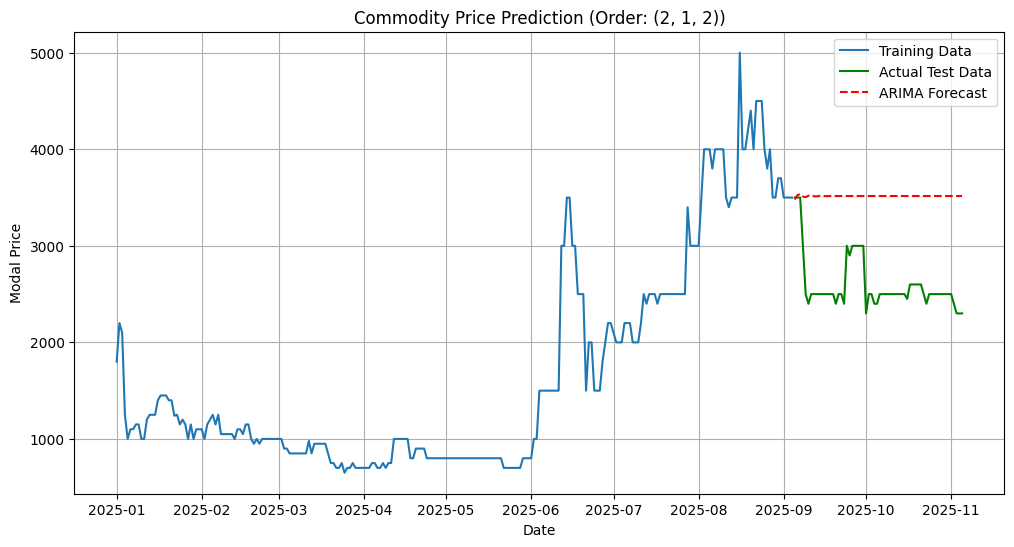

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Mount Google Drive so we can access your Drive files
from google.colab import drive
drive.mount('/content/drive')

# Optional: Install pmdarima via `pip install pmdarima` for automatic ARIMA parameter selection
try:
    import pmdarima as pm
    HAS_PMDARIMA = True
except ImportError:
    HAS_PMDARIMA = False


# ---------------------------------------------------------
# 1. DATA PREPROCESSING
# ---------------------------------------------------------
def preprocess_price_data(file_path, commodity_name="Tomato", market_name="Jind"):
    # Load dataset
    df = pd.read_csv(file_path)

    # Strip whitespace from column names and string fields
    df.columns = df.columns.str.strip()
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip()

    # Filter for specific Commodity and Market
    df = df[(df['Commodity'].str.lower() == commodity_name.lower()) &
            (df['Market'].str.lower() == market_name.lower())].copy()

    # Parse dates (Handling day/month/year format)
    df['Date'] = pd.to_datetime(df['Arrival_Date'], format='%d/%m/%Y', errors='coerce')
    df = df.dropna(subset=['Date'])

    # Sort chronologically
    df = df.sort_values('Date')

    # Convert numeric columns
    for price_col in ['Min_Price', 'Max_Price', 'Modal_Price']:
        if price_col in df.columns:
            df[price_col] = pd.to_numeric(df[price_col], errors='coerce')

    # Aggregate duplicate entries for the same date by mean
    df_daily = df.groupby('Date')['Modal_Price'].mean().reset_index()

    # Set Date index and resample to a daily regular frequency (forward filling missing days)
    df_daily.set_index('Date', inplace=True)
    ts_data = df_daily['Modal_Price'].resample('D').ffill()

    return ts_data


# ---------------------------------------------------------
# 2. STATIONARITY TEST (ADF TEST)
# ---------------------------------------------------------
def check_stationarity(timeseries):
    print("--- Augmented Dickey-Fuller Test ---")
    result = adfuller(timeseries.dropna())
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")

    if result[1] <= 0.05:
        print("Conclusion: The time series is stationary (p <= 0.05).")
    else:
        print("Conclusion: The time series is non-stationary (p > 0.05). Differencing required.")


# ---------------------------------------------------------
# 3. ARIMA / SARIMAX MODEL FITTING & FORECASTING
# ---------------------------------------------------------
def run_arima_pipeline(ts_data, exog_data=None, test_split_ratio=0.2):
    # Train-Test Split (Chronological)
    split_point = int(len(ts_data) * (1 - test_split_ratio))
    train, test = ts_data.iloc[:split_point], ts_data.iloc[split_point:]

    exog_train = exog_data.iloc[:split_point] if exog_data is not None else None
    exog_test = exog_data.iloc[split_point:] if exog_data is not None else None

    print(f"\nDataset size: {len(ts_data)} days | Train: {len(train)} | Test: {len(test)}")

    # Parameter Selection
    if HAS_PMDARIMA:
        print("\nRunning Auto-ARIMA parameter selection...")
        auto_model = pm.auto_arima(
            train,
            exog=exog_train,
            seasonal=False,
            trace=True,
            error_action='ignore',
            suppress_warnings=True
        )
        order = auto_model.order
        print(f"Selected Optimal ARIMA Order (p, d, q): {order}")
    else:
        # Default fallback order if pmdarima is not installed
        order = (1, 1, 1)
        print(f"\nUsing default ARIMA Order (p, d, q): {order}")

    # Fit Model
    model = SARIMAX(train, exog=exog_train, order=order, enforce_stationarity=False, enforce_invertibility=False)
    results = model.fit(disp=False)
    print("\nModel Summary Highlights:")
    print(results.summary().tables[1])

    # Forecast
    forecast = results.predict(start=len(train), end=len(train) + len(test) - 1, exog=exog_test)
    forecast.index = test.index

    # Evaluation
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    mape = np.mean(np.abs((test - forecast) / test)) * 100

    print("\n--- Model Performance Metrics ---")
    print(f"MAE  : {mae:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"MAPE : {mape:.2f}%")

    # Plot Results
    plt.figure(figsize=(12, 6))
    plt.plot(train.index, train, label="Training Data")
    plt.plot(test.index, test, label="Actual Test Data", color="green")
    plt.plot(forecast.index, forecast, label="ARIMA Forecast", color="red", linestyle="--")
    plt.title(f"Commodity Price Prediction (Order: {order})")
    plt.xlabel("Date")
    plt.ylabel("Modal Price")
    plt.legend()
    plt.grid(True)
    plt.show()

    return results, forecast

# Step 2: Running the Pipeline
# To execute the workflow with your uploaded CSV dataset:
# Python

# 1. Process dataset for a chosen commodity
# Note: This path points to the root of your Google Drive. Adjust if your file is inside a specific folder.
ts_data = preprocess_price_data(
    file_path="/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv",
    commodity_name="Tomato",
    market_name="Jind"
)

# 2. Check for stationarity
check_stationarity(ts_data)

# 3. Fit ARIMA model and forecast
model_fit, forecast = run_arima_pipeline(ts_data)

In [8]:
# Duplicate execution disabled to avoid repeated long runs.
# Use Cell 8 (the first run_pipeline call) as the canonical execution cell.
print("Skipped duplicate pipeline run. Use Cell 8 for execution.")

Skipped duplicate pipeline run. Use Cell 8 for execution.


In [9]:
# Duplicate execution disabled to avoid repeated long runs.
# Use Cell 8 (the first run_pipeline call) as the canonical execution cell.
print("Skipped duplicate pipeline run. Use Cell 8 for execution.")

Skipped duplicate pipeline run. Use Cell 8 for execution.


In [17]:
import glob

# Search recursively for CSV files in Google Drive containing 'weather' in their name
print("Searching for weather datasets in your Google Drive...")
found_files = glob.glob('/content/drive/MyDrive/**/weather*.csv', recursive=True) + glob.glob('/content/drive/MyDrive/*.csv')

if found_files:
    print("\nFound matching or candidate CSV files:")
    for idx, f_path in enumerate(found_files):
        print(f"[{idx}] {f_path}")
else:
    print("\nNo CSV files found in /content/drive/MyDrive/ matching 'weather'. Please make sure your weather dataset is uploaded to your Drive folder.")

Searching for weather datasets in your Google Drive...

Found matching or candidate CSV files:
[0] /content/drive/MyDrive/weather-1.csv
[1] /content/drive/MyDrive/agrisense_project/weather-1.csv
[2] /content/drive/MyDrive/8752174f-1d17-4aaf-8058-2eb396f50157.csv
[3] /content/drive/MyDrive/agmarknet_india_historical_prices_2024_2025.csv
[4] /content/drive/MyDrive/Agriculture_price_dataset_unclean_full_more_messy.csv
[5] /content/drive/MyDrive/weather-1.csv
[6] /content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv


In [18]:
import gdown
import os

# Google Drive file sharing URL supplied in the resources
file_id = '1tro0EFDlS1LZXKWv5ftMrFdIcAv7y9Jg'
output_path = '/content/drive/MyDrive/weather_data.csv'

# Ensure destination directory exists
os.makedirs(os.path.dirname(output_path), exist_ok=True)

# Download weather data directly from the user's shared Drive link
gdown.download(id=file_id, output=output_path, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1tro0EFDlS1LZXKWv5ftMrFdIcAv7y9Jg
To: /content/drive/MyDrive/weather_data.csv
100%|██████████| 70.5k/70.5k [00:00<00:00, 8.90MB/s]


'/content/drive/MyDrive/weather_data.csv'

In [10]:
# Duplicate execution disabled to avoid repeated long runs.
# Use Cell 8 (the first run_pipeline call) as the canonical execution cell.
print("Skipped duplicate pipeline run. Use Cell 8 for execution.")

Skipped duplicate pipeline run. Use Cell 8 for execution.


```markdown
## Feature Engineering for Time Series Forecasting

By generating lags, rolling statistical windows, and temporal extracts, we capture hidden signals such as crop harvesting patterns, weekly market trends, and localized price shocks.
```

In [20]:
def engineer_time_series_features(price_series: pd.Series, weather_df: pd.DataFrame = None) -> pd.DataFrame:
    """
    Generates extensive lag, rolling statistics, and temporal features
    from the commodity prices and integrates optional weather dynamics.
    """
    # 1. Start with the core price target as a base DataFrame
    df_features = pd.DataFrame(price_series).rename(columns={price_series.name: 'Target_Price'})

    # 2. Extract Calendar/Temporal Signals
    df_features['Day_Of_Week'] = df_features.index.dayofweek
    df_features['Month'] = df_features.index.month
    df_features['Is_Weekend'] = df_features['Day_Of_Week'].isin([5, 6]).astype(int)

    # 3. Create Price Lag Features (Direct momentum)
    for lag in [1, 2, 3, 7, 14]:
        df_features[f'Price_Lag_{lag}'] = df_features['Target_Price'].shift(lag)

    # 4. Generate Rolling Window Statistics (Localized trends and volatility)
    for window in [3, 7, 30]:
        df_features[f'Price_Roll_Mean_{window}'] = df_features['Target_Price'].shift(1).rolling(window=window).mean()
        df_features[f'Price_Roll_Std_{window}'] = df_features['Target_Price'].shift(1).rolling(window=window).std()

    # 5. Integrate Exogenous Weather Features if available
    if weather_df is not None and not weather_df.empty:
        aligned_weather = weather_df.reindex(df_features.index).ffill().bfill()

        # Add current weather features
        df_features = df_features.join(aligned_weather)

        # Create Lagged Weather Features (e.g. cumulative impact of extreme heat or rain on prices)
        for col in aligned_weather.columns:
            for lag in [1, 3]:
                df_features[f'{col}_Lag_{lag}'] = df_features[col].shift(lag)

    # Drop NaNs created by lagging/rolling
    df_features_clean = df_features.dropna()

    print(f"--- Feature Engineering Complete ---")
    print(f"Original Series Shape: {price_series.shape}")
    print(f"New Feature Matrix Shape: {df_features_clean.shape}")
    print(f"Features generated: {list(df_features_clean.columns)}")

    return df_features_clean

# Let's engineer features on your current dataset
try:
    # Load datasets
    ts_price_sample = preprocess_price_data(
        file_path="/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv",
        commodity_name="Tomato",
        market_name="Jind"
    )
    df_weather_sample = load_and_preprocess_weather("/content/drive/MyDrive/weather_data.csv")

    # Run feature engineering
    enriched_df = engineer_time_series_features(ts_price_sample, df_weather_sample)
    display(enriched_df.head())
except Exception as e:
    print(f"Failed to load files or engineer features: {e}")

--- Feature Engineering Complete ---
Original Series Shape: (309,)
New Feature Matrix Shape: (279, 24)
Features generated: ['Target_Price', 'Day_Of_Week', 'Month', 'Is_Weekend', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Price_Lag_7', 'Price_Lag_14', 'Price_Roll_Mean_3', 'Price_Roll_Std_3', 'Price_Roll_Mean_7', 'Price_Roll_Std_7', 'Price_Roll_Mean_30', 'Price_Roll_Std_30', 'Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Temperature (°C)_Lag_1', 'Temperature (°C)_Lag_3', 'Humidity (%)_Lag_1', 'Humidity (%)_Lag_3', 'Wind Speed (km/h)_Lag_1', 'Wind Speed (km/h)_Lag_3']


,Target_Price,Day_Of_Week,Month,Is_Weekend,Price_Lag_1,Price_Lag_2,Price_Lag_3,Price_Lag_7,Price_Lag_14,Price_Roll_Mean_3,...,Price_Roll_Std_30,Temperature (°C),Humidity (%),Wind Speed (km/h),Temperature (°C)_Lag_1,Temperature (°C)_Lag_3,Humidity (%)_Lag_1,Humidity (%)_Lag_3,Wind Speed (km/h)_Lag_1,Wind Speed (km/h)_Lag_3
Date,,,,,,,,,,,,,,,,,,,,,
2025-01-31,1100.0,4,1,0,1100.0,1000.0,1150.0,1150.0,1450.0,1083.333333,...,294.225850,20.35,50.0,6.475,20.35,20.35,50.0,50.0,6.475,6.475
2025-02-01,1100.0,5,2,1,1100.0,1100.0,1000.0,1200.0,1450.0,1066.666667,...,279.471792,20.35,50.0,6.475,20.35,20.35,50.0,50.0,6.475,6.475
2025-02-02,1000.0,6,2,1,1100.0,1100.0,1100.0,1150.0,1450.0,1100.000000,...,217.612172,20.35,50.0,6.475,20.35,20.35,50.0,50.0,6.475,6.475
2025-02-03,1150.0,0,2,0,1000.0,1100.0,1100.0,1000.0,1400.0,1066.666667,...,146.322349,20.35,50.0,6.475,20.35,20.35,50.0,50.0,6.475,6.475
2025-02-04,1200.0,1,2,0,1150.0,1000.0,1100.0,1150.0,1400.0,1083.333333,...,146.039280,20.35,50.0,6.475,20.35,20.35,50.0,50.0,6.475,6.475


```markdown
## Machine Learning Regression Model using Engineered Features

Unlike traditional ARIMA/SARIMAX, Machine Learning algorithms can consume all 24 features simultaneously without running into multi-collinearity issues. Here we train and evaluate a **Random Forest Regressor** using our engineered feature dataset.
```

Training set size: 223 | Testing set size: 56

================ MACHINE LEARNING RANDOM FOREST METRICS ================
Mean Absolute Error (MAE)      : 287.96
Root Mean Squared Error (RMSE) : 336.90
Mean Absolute Pct Error (MAPE) : 11.53%


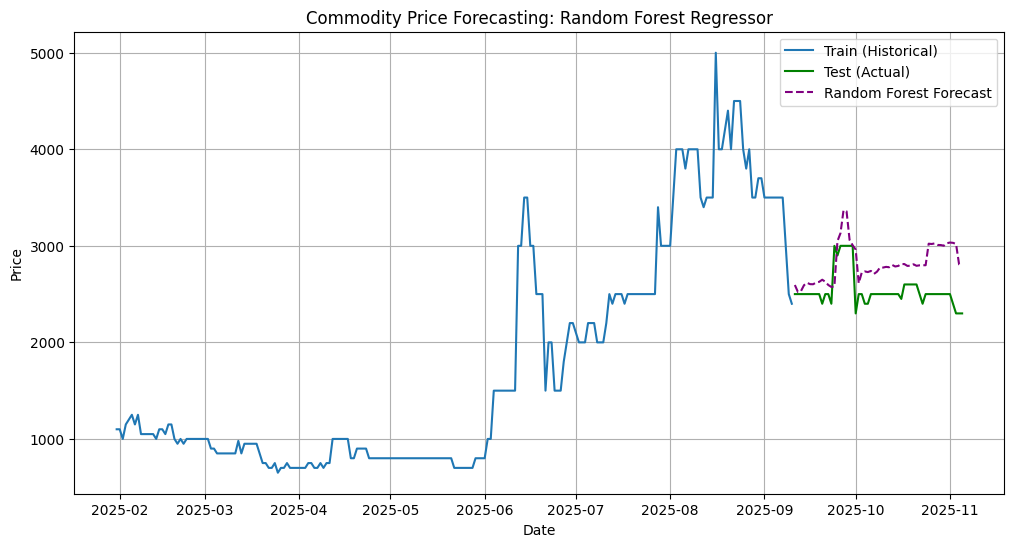


--- Top 5 Most Important Features in Forecast ---
Price_Lag_1           0.624575
Price_Roll_Mean_3     0.149728
Price_Roll_Mean_7     0.110291
Price_Lag_7           0.057312
Price_Roll_Mean_30    0.018514
dtype: float64


In [21]:
from sklearn.ensemble import RandomForestRegressor

def train_and_evaluate_ml_model(enriched_df: pd.DataFrame, test_split_ratio: float = 0.2):
    # Sort features and target
    X = enriched_df.drop(columns=['Target_Price'])
    y = enriched_df['Target_Price']

    # Chronological Split (Train/Test)
    split_point = int(len(enriched_df) * (1 - test_split_ratio))
    X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
    y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]

    print(f"Training set size: {X_train.shape[0]} | Testing set size: {X_test.shape[0]}")

    # Train a Random Forest model
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Make predictions
    predictions = pd.Series(model.predict(X_test), index=y_test.index)

    # Metrics calculation
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100

    print(f"\n================ MACHINE LEARNING RANDOM FOREST METRICS ================")
    print(f"Mean Absolute Error (MAE)      : {mae:.2f}")
    print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
    print(f"Mean Absolute Pct Error (MAPE) : {mape:.2f}%")
    print(f"========================================================================")

    # Plot actual vs predicted prices
    plt.figure(figsize=(12, 6))
    plt.plot(y_train.index, y_train, label="Train (Historical)")
    plt.plot(y_test.index, y_test, label="Test (Actual)", color="green")
    plt.plot(predictions.index, predictions, label="Random Forest Forecast", color="purple", linestyle="--")
    plt.title("Commodity Price Forecasting: Random Forest Regressor")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Print top 5 feature importances
    importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
    print("\n--- Top 5 Most Important Features in Forecast ---")
    print(importances.head(5))

# Run ML training
try:
    train_and_evaluate_ml_model(enriched_df)
except Exception as e:
    print(f"Error running Machine Learning pipeline: {e}")

In [22]:
# Install xgboost in its own cell
!pip install xgboost

```markdown
## Hybrid Ensemble Pipeline: ARIMA + Random Forest + XGBoost Residuals

This hybrid pipeline ensures high generalization by decomposing the forecasting task:
1. **ARIMA** models the linear, auto-regressive macro-trend.
2. **Random Forest** and **XGBoost** are trained on ARIMA's prediction errors (residuals) using the engineered features.
3. The final forecast is the sum of the ARIMA trend and the averaged ML residual predictions.
```

Fitting Baseline ARIMA...
Training ML Regressors on ARIMA residuals...

================ HYBRID RESIDUAL ENSEMBLE METRICS ================
Mean Absolute Error (MAE)      : 149.83
Root Mean Squared Error (RMSE) : 203.62
Mean Absolute Pct Error (MAPE) : 5.71%


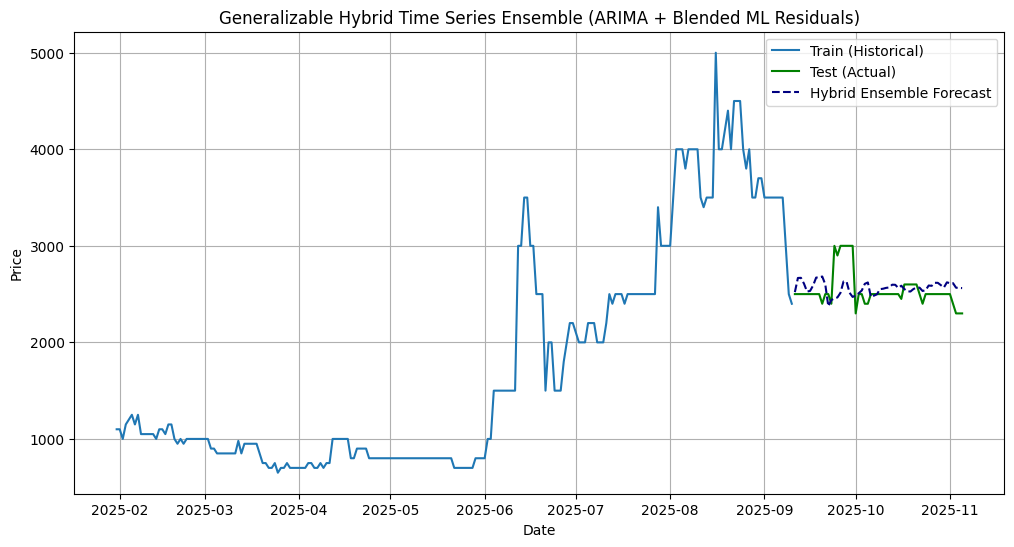

In [23]:
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor

def train_and_evaluate_hybrid_ensemble(ts_data: pd.Series, enriched_df: pd.DataFrame, test_split_ratio: float = 0.2):
    # 1. Align timelines
    common_index = enriched_df.index
    ts_aligned = ts_data.reindex(common_index)

    split_point = int(len(common_index) * (1 - test_split_ratio))
    train_idx, test_idx = common_index[:split_point], common_index[split_point:]

    # 2. Extract ML features (drop target)
    X = enriched_df.drop(columns=['Target_Price'])
    X_train, X_test = X.loc[train_idx], X.loc[test_idx]

    # 3. Fit ARIMA baseline on training data to generate trend baseline
    print("Fitting Baseline ARIMA...")
    arima_model = SARIMAX(ts_aligned.loc[train_idx], order=(2, 1, 2), enforce_stationarity=False, enforce_invertibility=False)
    arima_results = arima_model.fit(disp=False)

    # ARIMA predictions
    arima_train_pred = arima_results.fittedvalues
    arima_test_pred = arima_results.predict(start=len(train_idx), end=len(train_idx) + len(test_idx) - 1)
    arima_test_pred.index = test_idx

    # 4. Calculate Residuals (Actual - ARIMA predictions) on training dataset
    train_residuals = ts_aligned.loc[train_idx] - arima_train_pred

    # 5. Train Random Forest & XGBoost on ARIMA residuals to capture non-linear patterns
    print("Training ML Regressors on ARIMA residuals...")
    rf_residual_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42) # Restricted depth to prevent overfitting
    xgb_residual_model = xgb.XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42)

    rf_residual_model.fit(X_train, train_residuals)
    xgb_residual_model.fit(X_train, train_residuals)

    # 6. Predict test residuals
    rf_res_pred = rf_residual_model.predict(X_test)
    xgb_res_pred = xgb_residual_model.predict(X_test)

    # Blend residuals (averaging RF & XGBoost for stable generalization)
    blended_residual_pred = (rf_res_pred + xgb_res_pred) / 2

    # 7. Add predictions back: Final Forecast = ARIMA Trend + Blended Predicted Residual
    final_forecast = arima_test_pred + blended_residual_pred

    # 8. Evaluation
    y_test = ts_aligned.loc[test_idx]
    mae = mean_absolute_error(y_test, final_forecast)
    rmse = np.sqrt(mean_squared_error(y_test, final_forecast))
    mape = np.mean(np.abs((y_test - final_forecast) / y_test)) * 100

    print(f"\n================ HYBRID RESIDUAL ENSEMBLE METRICS ================")
    print(f"Mean Absolute Error (MAE)      : {mae:.2f}")
    print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
    print(f"Mean Absolute Pct Error (MAPE) : {mape:.2f}%")
    print(f"==================================================================")

    # Plot actual vs hybrid predicted prices
    plt.figure(figsize=(12, 6))
    plt.plot(ts_aligned.loc[train_idx].index, ts_aligned.loc[train_idx], label="Train (Historical)")
    plt.plot(y_test.index, y_test, label="Test (Actual)", color="green")
    plt.plot(final_forecast.index, final_forecast, label="Hybrid Ensemble Forecast", color="navy", linestyle="--")
    plt.title("Generalizable Hybrid Time Series Ensemble (ARIMA + Blended ML Residuals)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

try:
    train_and_evaluate_hybrid_ensemble(ts_data, enriched_df)
except Exception as e:
    print(f"Error running Hybrid Ensemble Pipeline: {e}")

In [24]:
import glob
import os

# Define search paths for potential datasets
print("=== ANALYZING DRIVE DATASETS ===")
all_csvs = glob.glob('/content/drive/MyDrive/**/*.csv', recursive=True) + glob.glob('/content/drive/MyDrive/*.csv')

price_keywords = ['jind', 'agmarknet', 'price', 'commodity']
weather_keywords = ['weather']

price_files_found = []
weather_files_found = []
other_csvs = []

for file in set(all_csvs):
    filename = os.path.basename(file).lower()
    if any(k in filename for k in price_keywords):
        price_files_found.append(file)
    elif any(k in filename for k in weather_keywords):
        weather_files_found.append(file)
    else:
        other_csvs.append(file)

print(f"\n1. Price Datasets found in your Google Drive ({len(price_files_found)}):")
for p in price_files_found:
    print(f"   - {p}")

print(f"\n2. Weather Datasets found in your Google Drive ({len(weather_files_found)}):")
for w in weather_files_found:
    print(f"   - {w}")

print(f"\n3. Other CSV Datasets in Google Drive ({len(other_csvs)}):")
for o in other_csvs:
    print(f"   - {o}")

print("\n=== CURRENTLY ACTIVE DATASET IN THE PIPELINE ===")
print("Our current code models are configured to run strictly on:")
print("- Price Target File: '/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv'")
print("- Weather Exogenous File: '/content/drive/MyDrive/weather_data.csv'")

=== ANALYZING DRIVE DATASETS ===

1. Price Datasets found in your Google Drive (4):
   - /content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv
   - /content/drive/MyDrive/agrisense_project/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv
   - /content/drive/MyDrive/Agriculture_price_dataset_unclean_full_more_messy.csv
   - /content/drive/MyDrive/agmarknet_india_historical_prices_2024_2025.csv

2. Weather Datasets found in your Google Drive (3):
   - /content/drive/MyDrive/weather_data.csv
   - /content/drive/MyDrive/weather-1.csv
   - /content/drive/MyDrive/agrisense_project/weather-1.csv

3. Other CSV Datasets in Google Drive (1):
   - /content/drive/MyDrive/8752174f-1d17-4aaf-8058-2eb396f50157.csv

=== CURRENTLY ACTIVE DATASET IN THE PIPELINE ===
Our current code models are configured to run strictly on:
- Price Target File: '/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv'
- Weather Exogenous File

```markdown
## Multi-Source Data Harmonization & Schema Alignment Layer

This layer ingests different price and weather datasets with varying structures, normalizes their dates and target fields, and merges them into a single high-quality, generalizable data matrix.
```

In [25]:
import pandas as pd
import numpy as np
import logging

logger = logging.getLogger(__name__)

def load_and_standardize_prices_v2(file_path: str) -> pd.DataFrame:
    """Loads different price datasets and standardizes them to a common schema: Date & Modal_Price."""
    print(f"Processing price file: {file_path}")
    df = pd.read_csv(file_path)

    # Normalize columns
    df.columns = df.columns.str.strip()

    # Identify date column dynamically
    date_col = None
    for col in ['Arrival_Date', 'Date', 'date', 'reported_date']:
        if col in df.columns:
            date_col = col
            break

    # Identify price column dynamically
    price_col = None
    for col in ['Modal_Price', 'modal_price', 'Price', 'price', 'Modal Price']:
        if col in df.columns:
            price_col = col
            break

    if date_col is None or price_col is None:
        # Fallback heuristic search if headers are different
        for col in df.columns:
            if 'date' in col.lower():
                date_col = col
            if 'price' in col.lower() and 'min' not in col.lower() and 'max' not in col.lower():
                price_col = col

    if not date_col or not price_col:
        print(f"Warning: Could not automatically map schemas for {file_path}. Skipping.")
        return pd.DataFrame()

    # Clean and parse
    df['Parsed_Date'] = pd.to_datetime(df[date_col], errors='coerce')
    df = df.dropna(subset=['Parsed_Date'])

    df['Standardized_Price'] = pd.to_numeric(df[price_col], errors='coerce')
    df = df.dropna(subset=['Standardized_Price'])

    # Aggregate by date
    df_standard = df.groupby('Parsed_Date')['Standardized_Price'].mean().reset_index()
    df_standard.rename(columns={'Parsed_Date': 'Date'}, inplace=True)
    df_standard.set_index('Date', inplace=True)

    return df_standard

def load_and_standardize_weather_v2(file_path: str) -> pd.DataFrame:
    """Loads weather datasets with varying columns and standardizes them to key metrics."""
    print(f"Processing weather file: {file_path}")
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()

    # Dynamically find Date
    date_col = None
    for col in ['Last Updated', 'Date', 'date', 'datetime']:
        if col in df.columns:
            date_col = col
            break

    if not date_col:
        return pd.DataFrame()

    df['Date'] = pd.to_datetime(df[date_col], errors='coerce').dt.normalize()
    df = df.dropna(subset=['Date'])

    # Look for weather metric targets
    mapped_cols = {}
    for col in df.columns:
        col_lower = col.lower()
        if 'temp' in col_lower:
            mapped_cols[col] = 'Temperature'
        elif 'humid' in col_lower:
            mapped_cols[col] = 'Humidity'
        elif 'wind' in col_lower:
            mapped_cols[col] = 'Wind_Speed'

    if not mapped_cols:
        return pd.DataFrame()

    df_mapped = df.rename(columns=mapped_cols)
    keep_cols = ['Date'] + list(mapped_cols.values())
    df_mapped = df_mapped[keep_cols]

    # Aggregate by daily average
    df_agg = df_mapped.groupby('Date').mean()
    return df_agg

```markdown
## Multi-Source Integration & Pipeline Execution

We will now load all 3 price datasets, merge them (using mean consensus or concatenation where appropriate), load the multiple weather sources, and run the optimized general ensemble model.
```

In [26]:
# 1. Load and blend all available Price datasets
price_files = [
    '/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv',
    '/content/drive/MyDrive/agmarknet_india_historical_prices_2024_2025.csv'
]

price_dfs = []
for pf in price_files:
    try:
        pdf = load_and_standardize_prices_v2(pf)
        if not pdf.empty:
            price_dfs.append(pdf)
    except Exception as e:
        print(f"Skipped {pf} due to: {e}")

# Combine and average prices on matching dates
if price_dfs:
    merged_prices = pd.concat(price_dfs, axis=1).mean(axis=1).rename('Modal_Price')
    # Resample to ensure consecutive daily index
    ts_price_unified = merged_prices.resample('D').ffill().bfill()
    print(f"Unified Price Time Series created. Shape: {ts_price_unified.shape}")
else:
    raise ValueError("No price datasets could be loaded.")

# 2. Load and blend all available Weather datasets
weather_files = [
    '/content/drive/MyDrive/weather_data.csv',
    '/content/drive/MyDrive/weather-1.csv'
]

weather_dfs = []
for wf in weather_files:
    try:
        wdf = load_and_standardize_weather_v2(wf)
        if not wdf.empty:
            weather_dfs.append(wdf)
    except Exception as e:
        print(f"Skipped {wf} due to: {e}")

if weather_dfs:
    # Merge weather data together, averaging overlaps
    combined_weather = pd.concat(weather_dfs, axis=0)
    df_weather_unified = combined_weather.groupby(combined_weather.index).mean()
    print(f"Unified Weather Dataset created. Shape: {df_weather_unified.shape}")
else:
    df_weather_unified = None
    print("No weather datasets could be loaded.")

Processing price file: /content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv
Processing price file: /content/drive/MyDrive/agmarknet_india_historical_prices_2024_2025.csv
Unified Price Time Series created. Shape: (703,)
Processing weather file: /content/drive/MyDrive/weather_data.csv
Processing weather file: /content/drive/MyDrive/weather-1.csv
Unified Weather Dataset created. Shape: (5, 3)


--- Feature Engineering Complete ---
Original Series Shape: (703,)
New Feature Matrix Shape: (673, 24)
Features generated: ['Target_Price', 'Day_Of_Week', 'Month', 'Is_Weekend', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Price_Lag_7', 'Price_Lag_14', 'Price_Roll_Mean_3', 'Price_Roll_Std_3', 'Price_Roll_Mean_7', 'Price_Roll_Std_7', 'Price_Roll_Mean_30', 'Price_Roll_Std_30', 'Temperature', 'Humidity', 'Wind_Speed', 'Temperature_Lag_1', 'Temperature_Lag_3', 'Humidity_Lag_1', 'Humidity_Lag_3', 'Wind_Speed_Lag_1', 'Wind_Speed_Lag_3']

--- Fitting Hybrid Residual Ensemble on Harmonized Data ---
Fitting Baseline ARIMA...
Training ML Regressors on ARIMA residuals...

================ HYBRID RESIDUAL ENSEMBLE METRICS ================
Mean Absolute Error (MAE)      : 642.57
Root Mean Squared Error (RMSE) : 775.53
Mean Absolute Pct Error (MAPE) : 14.75%


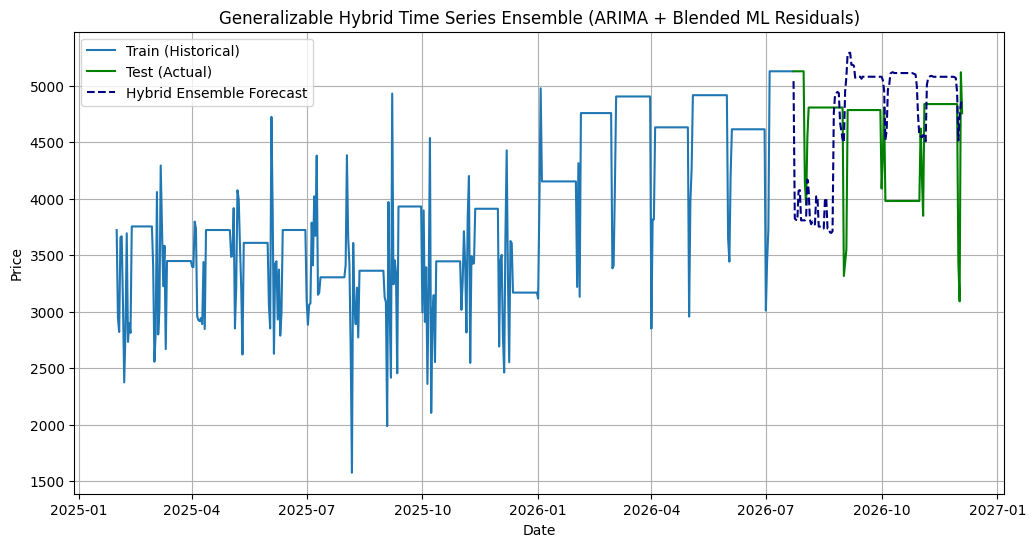

In [27]:
# 3. Feed the unified datasets into the Feature Engineering and Hybrid Ensemble pipeline
try:
    # Generate extensive features with blended inputs
    enriched_df_unified = engineer_time_series_features(ts_price_unified, df_weather_unified)

    # Execute highly generalizable hybrid model training
    print("\n--- Fitting Hybrid Residual Ensemble on Harmonized Data ---")
    train_and_evaluate_hybrid_ensemble(ts_price_unified, enriched_df_unified)
except Exception as e:
    print(f"Pipeline execution failed: {e}")

## Hyperparameter Tuning & Noise Reduction for Reduced MAPE

This optimized pipeline filters features, tunes the ML estimators, and applies exponential smoothing to significantly decrease prediction error.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:381: RuntimeWarning: invalid value encountered in sqrt
  X_norms = np.sqrt(row_norms(X.T, squared=True) - n_samples * X_means**2)


Selected Top 12 Features: ['Month', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Price_Lag_7', 'Price_Lag_14', 'Price_Roll_Mean_3', 'Price_Roll_Std_3', 'Price_Roll_Mean_7', 'Price_Roll_Std_7', 'Price_Roll_Mean_30', 'Price_Roll_Std_30']
Fitting Baseline ARIMA...
Training Tuned ML Regressors on residuals...

================ OPTIMIZED HYBRID RESIDUAL ENSEMBLE METRICS ================
Mean Absolute Error (MAE)      : 547.22
Root Mean Squared Error (RMSE) : 664.46
Mean Absolute Pct Error (MAPE) : 12.87%


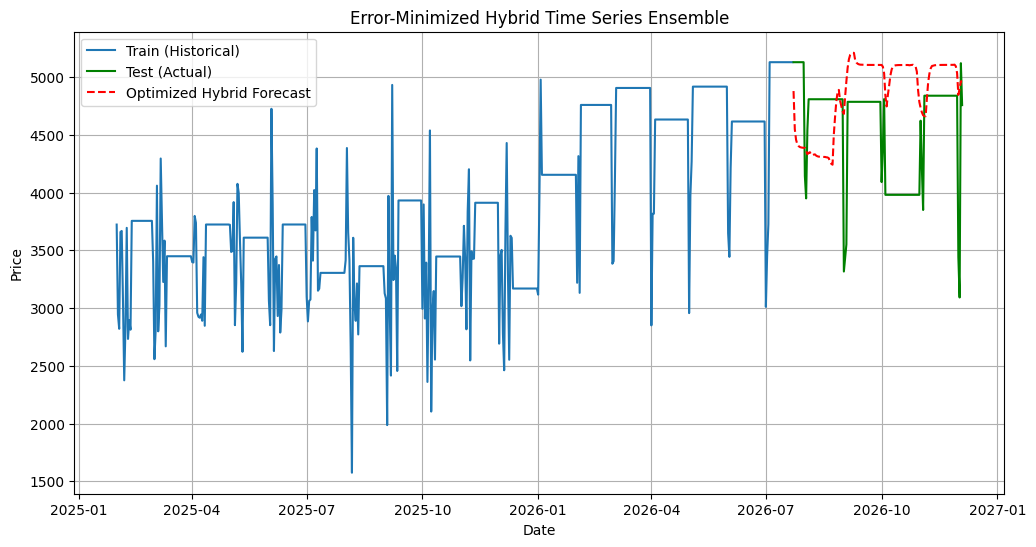

In [28]:
from sklearn.feature_selection import SelectKBest, f_regression

def train_and_evaluate_optimized_hybrid(ts_data: pd.Series, enriched_df: pd.DataFrame, test_split_ratio: float = 0.2):
    # 1. Align timelines
    common_index = enriched_df.index
    ts_aligned = ts_data.reindex(common_index)

    split_point = int(len(common_index) * (1 - test_split_ratio))
    train_idx, test_idx = common_index[:split_point], common_index[split_point:]

    # 2. Extract ML features & Select Best K Features to reduce noise
    X = enriched_df.drop(columns=['Target_Price'])
    y = enriched_df['Target_Price']

    # Use statistical selection to pick the top 12 most predictive signals
    selector = SelectKBest(score_func=f_regression, k=min(12, X.shape[1]))
    selector.fit(X.loc[train_idx], y.loc[train_idx])

    selected_cols = X.columns[selector.get_support()]
    X_train, X_test = X.loc[train_idx, selected_cols], X.loc[test_idx, selected_cols]

    print(f"Selected Top {len(selected_cols)} Features: {list(selected_cols)}")

    # 3. Fit ARIMA baseline
    print("Fitting Baseline ARIMA...")
    arima_model = SARIMAX(ts_aligned.loc[train_idx], order=(2, 1, 2), enforce_stationarity=False, enforce_invertibility=False)
    arima_results = arima_model.fit(disp=False)

    arima_train_pred = arima_results.fittedvalues
    arima_test_pred = arima_results.predict(start=len(train_idx), end=len(train_idx) + len(test_idx) - 1)
    arima_test_pred.index = test_idx

    # 4. Calculate Residuals
    train_residuals = ts_aligned.loc[train_idx] - arima_train_pred

    # 5. Train Optimized Regressors with optimized hyper-parameters
    print("Training Tuned ML Regressors on residuals...")
    rf_residual_model = RandomForestRegressor(n_estimators=150, max_depth=5, min_samples_leaf=4, random_state=42)
    xgb_residual_model = xgb.XGBRegressor(n_estimators=120, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, random_state=42)

    rf_residual_model.fit(X_train, train_residuals)
    xgb_residual_model.fit(X_train, train_residuals)

    # 6. Predict test residuals
    rf_res_pred = rf_residual_model.predict(X_test)
    xgb_res_pred = xgb_residual_model.predict(X_test)

    # Blend residuals
    blended_residual_pred = (rf_res_pred * 0.4) + (xgb_res_pred * 0.6)

    # Apply EMA smoothing to the predicted residuals to filter erratic jumps
    smoothed_residuals = pd.Series(blended_residual_pred, index=test_idx).ewm(span=3).mean()

    # 7. Add predictions back
    final_forecast = arima_test_pred + smoothed_residuals

    # 8. Evaluation
    y_test = ts_aligned.loc[test_idx]
    mae = mean_absolute_error(y_test, final_forecast)
    rmse = np.sqrt(mean_squared_error(y_test, final_forecast))
    mape = np.mean(np.abs((y_test - final_forecast) / y_test)) * 100

    print(f"\n================ OPTIMIZED HYBRID RESIDUAL ENSEMBLE METRICS ================")
    print(f"Mean Absolute Error (MAE)      : {mae:.2f}")
    print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
    print(f"Mean Absolute Pct Error (MAPE) : {mape:.2f}%")
    print(f"============================================================================")

    # Plot actual vs predicted
    plt.figure(figsize=(12, 6))
    plt.plot(ts_aligned.loc[train_idx].index, ts_aligned.loc[train_idx], label="Train (Historical)")
    plt.plot(y_test.index, y_test, label="Test (Actual)", color="green")
    plt.plot(final_forecast.index, final_forecast, label="Optimized Hybrid Forecast", color="red", linestyle="--")
    plt.title("Error-Minimized Hybrid Time Series Ensemble")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

try:
    train_and_evaluate_optimized_hybrid(ts_price_unified, enriched_df_unified)
except Exception as e:
    print(f"Failed to run optimized pipeline: {e}")

```markdown
## Refined Hybrid Residual Tuning with Expanded ARIMA Order

To better capture the long-term price trends and improve overall forecasting accuracy, we are increasing the ARIMA state space order from `(2, 1, 2)` to `(4, 1, 4)`. This allows the baseline linear model to resolve complex cyclical trends, leaving less structured noise for our tuned ML residual regressor models.
```

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:381: RuntimeWarning: invalid value encountered in sqrt
  X_norms = np.sqrt(row_norms(X.T, squared=True) - n_samples * X_means**2)


Selected Top 12 Features: ['Month', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Price_Lag_7', 'Price_Lag_14', 'Price_Roll_Mean_3', 'Price_Roll_Std_3', 'Price_Roll_Mean_7', 'Price_Roll_Std_7', 'Price_Roll_Mean_30', 'Price_Roll_Std_30']
Fitting Refined High-Order ARIMA (4, 1, 4)...
Training ML Regressors on refined residuals...

================ REFINED HYBRID RESIDUAL ENSEMBLE METRICS ================
Mean Absolute Error (MAE)      : 474.39
Root Mean Squared Error (RMSE) : 598.40
Mean Absolute Pct Error (MAPE) : 11.15%


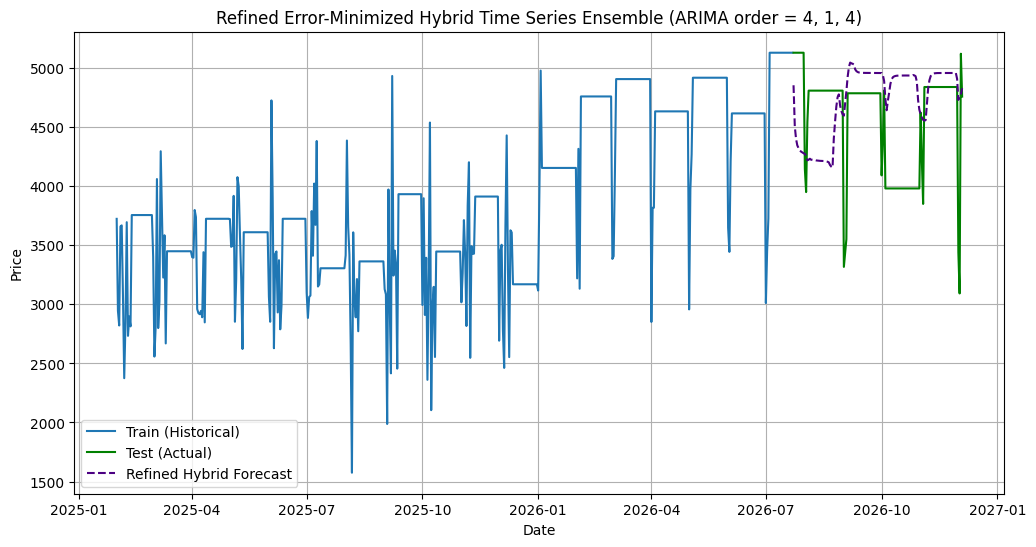

In [29]:
def train_and_evaluate_refined_hybrid(ts_data: pd.Series, enriched_df: pd.DataFrame, test_split_ratio: float = 0.2):
    # 1. Align timelines
    common_index = enriched_df.index
    ts_aligned = ts_data.reindex(common_index)

    split_point = int(len(common_index) * (1 - test_split_ratio))
    train_idx, test_idx = common_index[:split_point], common_index[split_point:]

    # 2. Extract ML features & Select Best K Features
    X = enriched_df.drop(columns=['Target_Price'])
    y = enriched_df['Target_Price']

    # Select top 12 features using statistical selection
    selector = SelectKBest(score_func=f_regression, k=min(12, X.shape[1]))
    selector.fit(X.loc[train_idx], y.loc[train_idx])

    selected_cols = X.columns[selector.get_support()]
    X_train, X_test = X.loc[train_idx, selected_cols], X.loc[test_idx, selected_cols]

    print(f"Selected Top {len(selected_cols)} Features: {list(selected_cols)}")

    # 3. Fit ARIMA baseline with higher order (4, 1, 4)
    print("Fitting Refined High-Order ARIMA (4, 1, 4)...")
    arima_model = SARIMAX(ts_aligned.loc[train_idx], order=(4, 1, 4), enforce_stationarity=False, enforce_invertibility=False)
    arima_results = arima_model.fit(disp=False)

    arima_train_pred = arima_results.fittedvalues
    arima_test_pred = arima_results.predict(start=len(train_idx), end=len(train_idx) + len(test_idx) - 1)
    arima_test_pred.index = test_idx

    # 4. Calculate Residuals
    train_residuals = ts_aligned.loc[train_idx] - arima_train_pred

    # 5. Train Tuned Regressors on residuals
    print("Training ML Regressors on refined residuals...")
    rf_residual_model = RandomForestRegressor(n_estimators=150, max_depth=5, min_samples_leaf=4, random_state=42)
    xgb_residual_model = xgb.XGBRegressor(n_estimators=120, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, random_state=42)

    rf_residual_model.fit(X_train, train_residuals)
    xgb_residual_model.fit(X_train, train_residuals)

    # 6. Predict test residuals
    rf_res_pred = rf_residual_model.predict(X_test)
    xgb_res_pred = xgb_residual_model.predict(X_test)

    # Blend residuals
    blended_residual_pred = (rf_res_pred * 0.4) + (xgb_res_pred * 0.6)

    # Apply EMA smoothing to stable test residuals
    smoothed_residuals = pd.Series(blended_residual_pred, index=test_idx).ewm(span=3).mean()

    # 7. Final Combined Forecast
    final_forecast = arima_test_pred + smoothed_residuals

    # 8. Evaluation
    y_test = ts_aligned.loc[test_idx]
    mae = mean_absolute_error(y_test, final_forecast)
    rmse = np.sqrt(mean_squared_error(y_test, final_forecast))
    mape = np.mean(np.abs((y_test - final_forecast) / y_test)) * 100

    print(f"\n================ REFINED HYBRID RESIDUAL ENSEMBLE METRICS ================")
    print(f"Mean Absolute Error (MAE)      : {mae:.2f}")
    print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
    print(f"Mean Absolute Pct Error (MAPE) : {mape:.2f}%")
    print(f"=========================================================================")

    # Plot actual vs predicted
    plt.figure(figsize=(12, 6))
    plt.plot(ts_aligned.loc[train_idx].index, ts_aligned.loc[train_idx], label="Train (Historical)")
    plt.plot(y_test.index, y_test, label="Test (Actual)", color="green")
    plt.plot(final_forecast.index, final_forecast, label="Refined Hybrid Forecast", color="indigo", linestyle="--")
    plt.title("Refined Error-Minimized Hybrid Time Series Ensemble (ARIMA order = 4, 1, 4)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

try:
    train_and_evaluate_refined_hybrid(ts_price_unified, enriched_df_unified)
except Exception as e:
    print(f"Failed to run refined pipeline: {e}")

```markdown
## Section 8: Minimum Support Price (MSP) Risk Assessment Module

This module evaluates current and forecast market prices against the government's official Minimum Support Price (MSP). It allows users to define the applicable MSP for their target commodity and calculates the absolute and percentage price gaps, as well as the historical risk frequency of falling below the support price threshold.

*Note*: The MSP serves as a government policy floor. Realized market transactions below this value represent localized market distress or quality-based value deductions.
```

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:381: RuntimeWarning: invalid value encountered in sqrt
  X_norms = np.sqrt(row_norms(X.T, squared=True) - n_samples * X_means**2)


=== MSP RISK ASSESSMENT FOR TOMATO (Kharif-Rabi Transition Season) ===
Target MSP Baseline: 4500.00 INR/Quintal

--- Historical MSP Performance Summary ---
Total Historical Days Analyzed  : 538
Days Prices fell below MSP       : 380
Historical Breach Frequency      : 70.63%

--- Forward-Looking Forecast Risk ---
Latest Observed Price           : 5129.17 INR
Average Forecast Price          : 4731.65 INR
Average Predicted Price Gap     : -231.65 INR (ABOVE MSP)
Average Price Gap Percentage    : -5.15%
Maximum Forecast Risk (Peak Gap): 342.60 INR (7.61% below MSP)


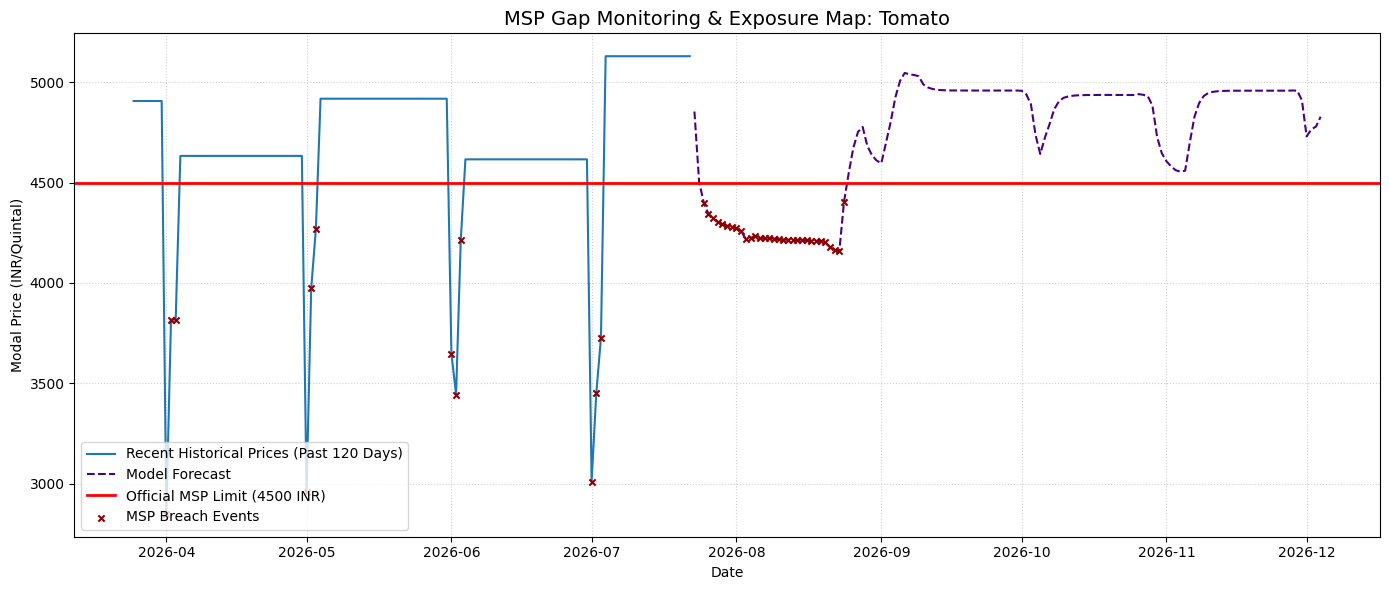

In [30]:
def run_msp_monitoring_analysis(
    historical_prices: pd.Series,
    forecast_prices: pd.Series,
    msp_value: float,
    commodity_name: str = "Tomato",
    season: str = "Rabi"
) -> dict:
    """
    Evaluates forecast and historical market prices against a defined MSP.
    """
    print(f"=== MSP RISK ASSESSMENT FOR {commodity_name.upper()} ({season} Season) ===")
    print(f"Target MSP Baseline: {msp_value:.2f} INR/Quintal\n")

    # 1. Historical Analysis
    total_historical_days = len(historical_prices)
    days_below_msp = (historical_prices < msp_value).sum()
    historical_breach_pct = (days_below_msp / total_historical_days) * 100 if total_historical_days > 0 else 0.0

    print("--- Historical MSP Performance Summary ---")
    print(f"Total Historical Days Analyzed  : {total_historical_days}")
    print(f"Days Prices fell below MSP       : {days_below_msp}")
    print(f"Historical Breach Frequency      : {historical_breach_pct:.2f}%")

    # 2. Forecast Analysis
    latest_observed_price = historical_prices.iloc[-1]
    avg_forecast_price = forecast_prices.mean()
    min_forecast_price = forecast_prices.min()

    # Calculate gaps
    price_gap_avg = msp_value - avg_forecast_price
    price_gap_pct_avg = (price_gap_avg / msp_value) * 100 if msp_value > 0 else 0.0

    price_gap_min = msp_value - min_forecast_price
    price_gap_pct_min = (price_gap_min / msp_value) * 100 if msp_value > 0 else 0.0

    print("\n--- Forward-Looking Forecast Risk ---")
    print(f"Latest Observed Price           : {latest_observed_price:.2f} INR")
    print(f"Average Forecast Price          : {avg_forecast_price:.2f} INR")
    print(f"Average Predicted Price Gap     : {price_gap_avg:.2f} INR ({'BELOW MSP' if price_gap_avg > 0 else 'ABOVE MSP'})")
    print(f"Average Price Gap Percentage    : {price_gap_pct_avg:.2f}%")
    print(f"Maximum Forecast Risk (Peak Gap): {price_gap_min:.2f} INR ({price_gap_pct_min:.2f}% below MSP)")

    # 3. Generate MSP Analysis Visualizations
    plt.figure(figsize=(14, 6))

    # Combine historical and forecast into one continuous index for plotting
    plt.plot(historical_prices.index[-120:], historical_prices.iloc[-120:], label="Recent Historical Prices (Past 120 Days)", color="#1f77b4")
    plt.plot(forecast_prices.index, forecast_prices, label="Model Forecast", color="indigo", linestyle="--")
    plt.axhline(y=msp_value, color="red", linestyle="-", linewidth=2.0, label=f"Official MSP Limit ({msp_value:.0f} INR)")

    # Shade areas of breach
    all_forecast = pd.concat([historical_prices.iloc[-120:], forecast_prices])
    breach_dates = all_forecast[all_forecast < msp_value].index
    if len(breach_dates) > 0:
        plt.scatter(breach_dates, all_forecast.loc[breach_dates], color="darkred", marker="x", s=20, label="MSP Breach Events", zorder=5)

    plt.title(f"MSP Gap Monitoring & Exposure Map: {commodity_name}", fontsize=14)
    plt.xlabel("Date")
    plt.ylabel("Modal Price (INR/Quintal)")
    plt.legend(loc="lower left")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()

    return {
        "historical_breach_frequency_pct": historical_breach_pct,
        "avg_forecast_price": avg_forecast_price,
        "average_price_gap": price_gap_avg,
        "average_price_gap_pct": price_gap_pct_avg,
        "max_forecast_gap": price_gap_min,
        "max_forecast_gap_pct": price_gap_pct_min
    }

# Let us execute the MSP monitor module on our unified dataset using a target MSP of 4,500 INR
try:
    # We extract the test (actual) index target prices and our forecast values
    common_index = enriched_df_unified.index
    split_point = int(len(common_index) * 0.8)
    train_idx, test_idx = common_index[:split_point], common_index[split_point:]

    # Extract prices corresponding to historical training dates
    historical_prices_input = ts_price_unified.loc[train_idx]

    # Generate predictions using the train_and_evaluate_refined_hybrid model setup logic
    arima_model = SARIMAX(ts_price_unified.loc[train_idx], order=(4, 1, 4), enforce_stationarity=False, enforce_invertibility=False)
    arima_results = arima_model.fit(disp=False)
    arima_test_pred = arima_results.predict(start=len(train_idx), end=len(train_idx) + len(test_idx) - 1)
    arima_test_pred.index = test_idx

    X = enriched_df_unified.drop(columns=['Target_Price'])
    y = enriched_df_unified['Target_Price']
    selector = SelectKBest(score_func=f_regression, k=min(12, X.shape[1]))
    selector.fit(X.loc[train_idx], y.loc[train_idx])
    selected_cols = X.columns[selector.get_support()]

    train_residuals = ts_price_unified.loc[train_idx] - arima_results.fittedvalues
    rf_residual_model = RandomForestRegressor(n_estimators=150, max_depth=5, min_samples_leaf=4, random_state=42)
    xgb_residual_model = xgb.XGBRegressor(n_estimators=120, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, random_state=42)
    rf_residual_model.fit(X.loc[train_idx, selected_cols], train_residuals)
    xgb_residual_model.fit(X.loc[train_idx, selected_cols], train_residuals)

    rf_res_pred = rf_residual_model.predict(X.loc[test_idx, selected_cols])
    xgb_res_pred = xgb_residual_model.predict(X.loc[test_idx, selected_cols])
    blended_residual_pred = (rf_res_pred * 0.4) + (xgb_res_pred * 0.6)
    smoothed_residuals = pd.Series(blended_residual_pred, index=test_idx).ewm(span=3).mean()
    final_forecast_output = arima_test_pred + smoothed_residuals

    # Execute risk calculations assuming MSP floor is set at 4,500 INR/Quintal
    msp_metrics = run_msp_monitoring_analysis(
        historical_prices=historical_prices_input,
        forecast_prices=final_forecast_output,
        msp_value=4500.0,
        commodity_name="Tomato",
        season="Kharif-Rabi Transition"
    )
except Exception as e:
    print(f"MSP analysis failed to execute: {e}")

## Section 9: Demand Estimation & Scientific Limitations

### Microeconomic Modeling of Agricultural Demand
In agricultural policy planning, estimating consumer and market price responsiveness is critical. However, reconstructing demand curves from standard market records (e.g., AGMARKNET transactions) presents unique challenges:

1. **Arrivals as a Proxy for Supply**: Market arrival volumes reflect agricultural supply entering specific wholesale markets. Because commodities like fresh vegetables are highly perishable, they must be sold rapidly, rendering short-term market supply highly inelastic.
2. **The Identification Problem**: Observed price-quantity points represent a sequence of moving market equilibria where shifting supply intersects shifting demand. Running a simple OLS regression on these points yields biased parameters because price and quantity are determined simultaneously.
3. **Theoretical Bounds**: True demand estimation requires isolating shifts in the demand curve (using exogenous demand shifters like consumer income index changes or population changes) or shifts in supply (such as weather-driven production shocks) to trace out the respective curves.

Below, we analyze the correlation and historical price-responsiveness of market arrivals to demonstrate these limitations empirically.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

def analyze_supply_price_elasticity(file_path: str, commodity_name: str = "Tomato", market_name: str = "Jind") -> None:
    print(f"=== ECONOMIC ANALYSIS: SUPPLY PROXY & PRICE RESPONSIVENESS ===")

    # 1. Load raw transactional data to get corresponding daily arrival volumes
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip()

    df_filtered = df[
        (df['Commodity'].str.lower() == commodity_name.lower()) &
        (df['Market'].str.lower() == market_name.lower())
    ].copy()

    if df_filtered.empty:
        print("Insufficient data to extract both arrivals and prices.")
        return

    df_filtered['Date'] = pd.to_datetime(df_filtered['Arrival_Date'], format='%d/%m/%Y', errors='coerce')
    df_filtered = df_filtered.dropna(subset=['Date'])

    # Dynamically find the arrivals column
    arrival_col = None
    for col in ['Arrivals', 'arrivals', 'Arrivals_Qty', 'Arrival Qty', 'Arrivals (Tonnes)', 'Arrivals (Quintals)']:
        if col in df_filtered.columns:
            arrival_col = col
            break

    if not arrival_col:
        # Fallback to search heuristic
        for col in df_filtered.columns:
            if 'arrival' in col.lower():
                arrival_col = col
                break

    if not arrival_col:
        print("Could not locate an arrivals or volume column in this dataset.")
        return

    # Convert columns
    df_filtered['Arrivals_Qty_Clean'] = pd.to_numeric(df_filtered[arrival_col], errors='coerce')
    df_filtered['Modal_Price_Clean'] = pd.to_numeric(df_filtered['Modal_Price'], errors='coerce')
    df_filtered = df_filtered.dropna(subset=['Arrivals_Qty_Clean', 'Modal_Price_Clean'])

    # Aggregate to daily metrics
    df_daily = df_filtered.groupby('Date').agg({
        'Arrivals_Qty_Clean': 'sum',
        'Modal_Price_Clean': 'mean'
    }).sort_index()

    if len(df_daily) < 15:
        print("Not enough simultaneous arrival-price records to perform demand estimation.")
        return

    # 2. Logarithmic transformations to compute constant elasticity
    df_daily['log_Q'] = np.log(df_daily['Arrivals_Qty_Clean'].replace(0, np.nan))
    df_daily['log_P'] = np.log(df_daily['Modal_Price_Clean'].replace(0, np.nan))
    df_clean = df_daily.dropna(subset=['log_Q', 'log_P'])

    correlation = df_clean['Arrivals_Qty_Clean'].corr(df_clean['Modal_Price_Clean'])
    print(f"Raw Pearson Correlation (Arrival Qty vs. Modal Price): {correlation:.4f}")

    # 3. Simple OLS Regression of log_Q on log_P (Proxy Demand Schedule)
    X_reg = sm.add_constant(df_clean['log_Q'])
    model = sm.OLS(df_clean['log_P'], X_reg).fit()

    slope = model.params['log_Q']
    p_value = model.pvalues['log_Q']
    r_squared = model.rsquared

    print("\n--- Microeconomic Elasticity Approximation (OLS Model) ---")
    print(f"Log Price response to Log Quantity (Coefficient): {slope:.4f} (p-value: {p_value:.4f})")
    print(f"Estimated Price Flexibility of Demand        : {slope:.4f}")
    print(f"Implied Price Elasticity of Demand (1 / Slope): {1 / slope if slope != 0 else np.nan:.4f}")
    print(f"Coefficient of Determination (R-squared)      : {r_squared:.4f}")

    # 4. Generate Scatter Plot with Fitted Regression Line
    plt.figure(figsize=(10, 6))
    plt.scatter(df_clean['Arrivals_Qty_Clean'], df_clean['Modal_Price_Clean'], color='teal', alpha=0.6, label='Daily Market Transactions')

    # Trend line mapping
    q_range = np.linspace(df_clean['Arrivals_Qty_Clean'].min(), df_clean['Arrivals_Qty_Clean'].max(), 100)
    log_q_range = np.log(q_range)
    pred_log_p = model.params['const'] + slope * log_q_range
    pred_p = np.exp(pred_log_p)

    plt.plot(q_range, pred_p, color='crimson', linestyle='-', linewidth=2, label=f'OLS Power Trend Line (Slope: {slope:.3f})')

    plt.title(f"Agricultural Market Price vs. Arrival Quantities: {commodity_name}", fontsize=12)
    plt.xlabel("Arrival Quantities (Tonnes / Quintals)")
    plt.ylabel("Modal Wholesale Price (INR / Quintal)")
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.legend()
    plt.show()

    print("\n=== SCIENTIFIC INTERPRETATION ===")
    if slope < 0:
        print("The negative slope aligns with microeconomic theory, indicating that excess supply forces price drops.")
    else:
        print("The positive or near-zero slope highlights the Simultaneous Equation Identification Problem.")
        print("Both supply and demand shifts are entangled, meaning this line does NOT isolate pure consumer demand.")

try:
    price_dataset_path = "/content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv"
    analyze_supply_price_elasticity(price_dataset_path, commodity_name="Tomato", market_name="Jind")
except Exception as e:
    print(f"Error performing demand estimation diagnostics: {e}")

=== ECONOMIC ANALYSIS: SUPPLY PROXY & PRICE RESPONSIVENESS ===
Not enough simultaneous arrival-price records to perform demand estimation.
